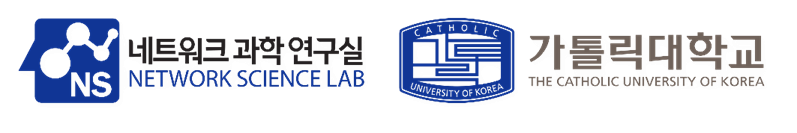

# Practice Code 13: GNNs for Recommendation Systems and Molecular Structure Learning


In Part I the graph is a user-item bipartite graph: there are no node features at all, the model has to invent them, and the edges we want to predict are the edges we are missing. 

In Part II the graph is a molecule: the nodes are atoms, the edges are bonds, and the hard part is that the useful information is not only in the bonds but in the 3-D positions of the atoms.

| Lecture | Section | What we build |
|:--|:--|:--|
| Tasks and metrics for RecSys | 1 | a bipartite graph from MovieLens, a chronological split, Recall@K and NDCG@K |
| Embedding-based models | 2 | score function, binary loss vs. BPR loss, matrix factorisation |
| NGCF | 3 | propagation of shallow embeddings along the bipartite graph |
| LightGCN | 4 | the same without $\mathbf W$ and without ReLU, layer combination |
| KGAT | 5 | a collaborative knowledge graph, TransR, attention over $(h, r, t)$ |
| ContextGNN | 6 | two-tower vs. pair-wise predictions, user-specific subgraphs, fusion |
| Molecules as graphs | 7 | a SMILES parser based on the five rules |
| Property prediction | 8 | GCN, GraphSAGE, GIN, GAT and a graph transformer on Tox21 and ESOL |
| Equivariant GNNs | 9 | the three equivariances, an invariant MPNN and the EGCL layer |
| Pre-training | 10 | attribute masking, contrastive learning, motif prediction |
| Uni-Mol | 11 | a distance-biased transformer, 3-D denoising pre-training |

# 0. Setup

In [1]:
INSTALL_DEPENDENCIES = False

if INSTALL_DEPENDENCIES:
    import subprocess, sys
    subprocess.check_call([sys.executable, "-m", "pip", "install", "torch", "numpy", "matplotlib"])

In [2]:
import os, re, sys, math, time, json, glob, gzip, random, zipfile, datetime, collections, itertools, warnings
warnings.filterwarnings("ignore")
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Device:', device, '| torch', torch.__version__)

def set_seed(seed=0):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

set_seed(0)
DATA = './data'
COLORS = {'Popularity': '#9a9a9a', 'MF': '#2a78d6', 'NGCF': '#1baf7a', 'LightGCN': '#e34948', 'KGAT': '#eda100',
          'ContextGNN': '#6250d6', 'Two-tower': '#e87ba4', 'Data': '#0b0b0b'}

Device: cuda | torch 2.14.0+cu130


# 1. A recommender system is a bipartite graph

## 1.1. The data: MovieLens with side information

We use HetRec 2011 MovieLens-2k (Cantador et al., RecSys 2011), the MovieLens-10M ratings of 2113 users, extended with the IMDb/Rotten-Tomatoes side information of the movies: directors, actors, genres, countries and years. The ratings give us the user-item interactions and the side information gives us the knowledge graph we will need for KGAT .

A recommender dataset is a list of (user, item, rating, timestamp). We turn it into implicit feedback: an edge exists when the user liked the movie (rating $\ge 4$ out of 5); everything else is treated as unobserved, not as negative.

855,598 ratings | 2,113 users | 10,109 movies


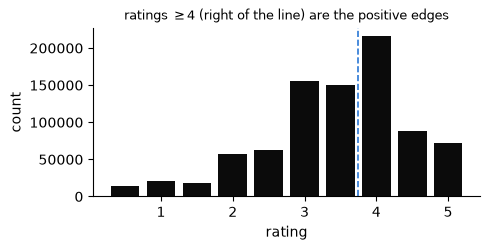

In [3]:
HETREC = f'{DATA}/hetrec/raw'

def read_table(name, path=HETREC):
    # the HetRec files are tab-separated, latin-1, with a header line
    with open(os.path.join(path, name), encoding='latin-1') as f:
        header = f.readline().rstrip('\r\n').split('\t')
        rows = [line.rstrip('\r\n').split('\t') for line in f if line.strip()]
    return header, rows

_, rows = read_table('user_ratedmovies-timestamps.dat')
RAW = np.array([[int(r[0]), int(r[1]), float(r[2]), int(r[3])] for r in rows])
print(f'{len(RAW):,} ratings | {len(np.unique(RAW[:, 0])):,} users | {len(np.unique(RAW[:, 1])):,} movies')

plt.figure(figsize=(5, 2.6))
vals, cnt = np.unique(RAW[:, 2], return_counts=True)
plt.bar(vals, cnt, width=0.4, color=COLORS['Data'])
plt.axvline(3.75, color=COLORS['MF'], ls='--', lw=1.2)
plt.xlabel('rating'); plt.ylabel('count'); plt.title('ratings $\\geq 4$ (right of the line) are the positive edges', fontsize=9)
plt.gca().spines[['top', 'right']].set_visible(False)
plt.tight_layout(); plt.show()

In [ ]:
def k_core(pairs, k=5):
    # repeatedly drop users and items with fewer than k interactions until nothing changes
    keep = pairs
    for _ in range(50):
        n0 = len(keep)
        for col in (1, 0):
            _, inv, cnt = np.unique(keep[:, col], return_inverse=True, return_counts=True)
            keep = keep[cnt[inv] >= k]
        if len(keep) == n0:
            return keep
    return keep

POS = k_core(RAW[RAW[:, 2] >= 4.0], k=5)
USER_IDS, U_ALL = np.unique(POS[:, 0].astype(int), return_inverse=True)      # original id -> 0..n_users-1
ITEM_IDS, I_ALL = np.unique(POS[:, 1].astype(int), return_inverse=True)
T_ALL = POS[:, 3].astype(np.int64)
N_USERS, N_ITEMS = len(USER_IDS), len(ITEM_IDS)

# movie titles, for the examples below
_, mrows = read_table('movies.dat')
TITLE = {int(r[0]): f'{r[1]} ({r[5]})' for r in mrows}
TITLES = [TITLE.get(m, str(m)) for m in ITEM_IDS]

print(f'{len(U_ALL):,} positive interactions | {N_USERS:,} users | {N_ITEMS:,} movies')
print(f'density = {len(U_ALL) / N_USERS / N_ITEMS:.4%}  (99.97% of the user-item matrix is unobserved)')
print(f'interactions per user: median {np.median(np.bincount(U_ALL)):.0f}, max {np.bincount(U_ALL).max()}')
print(f'interactions per item: median {np.median(np.bincount(I_ALL)):.0f}, max {np.bincount(I_ALL).max()}')

369,657 positive interactions | 2,102 users | 5,626 movies
density = 3.1258%  (99.97% of the user-item matrix is unobserved)
interactions per user: median 121, max 1537
interactions per item: median 21, max 1300


## 1.2. The bipartite graph

A recommender system is a graph with two node types, users and items, and an edge for every interaction. 

Nothing else is given — no node features. 

The only structure the model can use is who interacted with what.

Two properties of this graph decide everything that follows, and both are visible below:

* the degrees follow a power law: a few blockbusters absorb a large share of the edges, and most movies have very few. This is why recommend the most popular items is a strong baseline, and why we must always compare against it;

* the graph is extremely sparse (0.03% of the possible edges), so a model with one free parameter per user-item pair would have nothing to learn from.

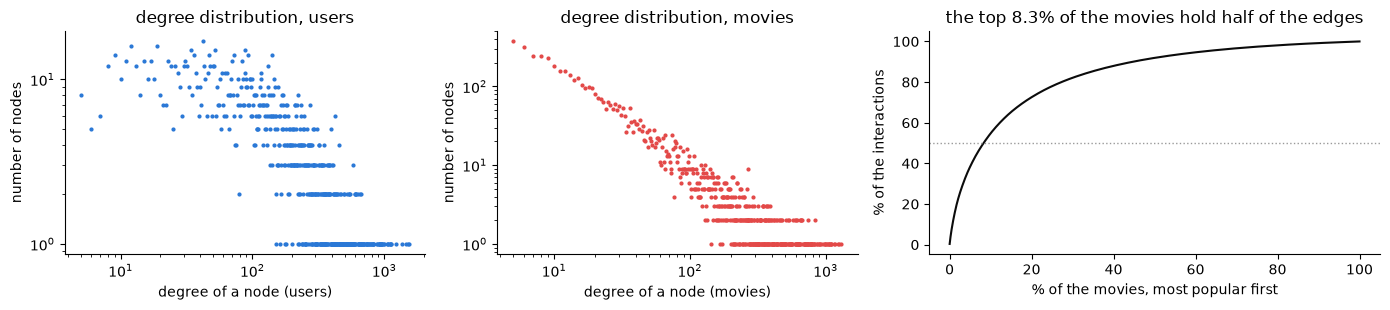

the 5 most popular movies:
   1300 users liked  The Matrix (1999)
   1249 users liked  Pulp Fiction (1994)
   1227 users liked  The Shawshank Redemption (1994)
   1168 users liked  The Lord of the Rings: The Fellowship of the Ring (2001)
   1145 users liked  Fight Club (1999)


In [5]:
deg_u, deg_i = np.bincount(U_ALL), np.bincount(I_ALL)

fig, axes = plt.subplots(1, 3, figsize=(14, 3.2), gridspec_kw=dict(width_ratios=[1, 1, 1.25]))
for ax, deg, name, col in [(axes[0], deg_u, 'users', COLORS['MF']), (axes[1], deg_i, 'movies', COLORS['LightGCN'])]:
    v, c = np.unique(deg, return_counts=True)
    ax.loglog(v, c, '.', color=col, ms=4)
    ax.set(xlabel=f'degree of a node ({name})', ylabel='number of nodes', title=f'degree distribution, {name}')
    ax.spines[['top', 'right']].set_visible(False)

order = np.argsort(-deg_i)
share = np.cumsum(deg_i[order]) / deg_i.sum()
axes[2].plot(np.arange(1, N_ITEMS + 1) / N_ITEMS * 100, share * 100, color=COLORS['Data'])
axes[2].axhline(50, color=COLORS['Popularity'], ls=':', lw=1)
axes[2].set(xlabel='% of the movies, most popular first', ylabel='% of the interactions',
            title=f'the top {np.searchsorted(share, 0.5) / N_ITEMS:.1%} of the movies hold half of the edges')
axes[2].spines[['top', 'right']].set_visible(False)
plt.tight_layout(); plt.show()

print('the 5 most popular movies:')
for k in order[:5]:
    print(f'  {deg_i[k]:>5} users liked  {TITLES[k]}')

## 1.3. The task and the split

Task: given the past interactions, predict the interactions of the future. If we split the edges at random, a model is allowed to see what a user watched in 2008 to predict what they watched in 2006, which is not the problem anyone has to solve in production.

We therefore split chronologically and per user: for every user, the oldest 80% of their liked movies are the training edges, the next 10% are validation and the newest 10% are the test targets. The graph the model propagates on is built from the training edges only.

In [6]:
def chronological_split(u, i, t, val=0.1, test=0.1):
    # per user: oldest 80% -> train, then 10% val, newest 10% test
    order = np.lexsort((i, t, u))
    u, i, t = u[order], i[order], t[order]
    split = np.zeros(len(u), dtype=np.int64)
    bounds = np.r_[0, np.flatnonzero(np.diff(u)) + 1, len(u)]
    for a, b in zip(bounds[:-1], bounds[1:]):
        n = b - a
        n_te = max(1, round(test * n)); n_va = max(1, round(val * n))
        split[b - n_te:b] = 2                                 # ★ KEY: the newest interactions are the test targets
        split[b - n_te - n_va:b - n_te] = 1
    return u, i, t, split

U, I, T, SPLIT = chronological_split(U_ALL, I_ALL, T_ALL)
TRAIN, VAL, TEST = SPLIT == 0, SPLIT == 1, SPLIT == 2
for name, m in [('train', TRAIN), ('valid', VAL), ('test', TEST)]:
    print(f'{name}: {m.sum():>7,} edges | {len(np.unique(U[m])):,} users | {len(np.unique(I[m])):,} movies')

cold = np.setdiff1d(np.unique(I[TEST]), np.unique(I[TRAIN]))
print(f'\nmovies that appear only in the test set: {len(cold)} ({np.isin(I[TEST], cold).sum()} test edges). '
      'No model without item features can ever recommend those.')

train: 295,707 edges | 2,102 users | 5,576 movies
valid:  36,975 edges | 2,102 users | 4,725 movies
test:  36,975 edges | 2,102 users | 4,631 movies

movies that appear only in the test set: 50 (326 test edges). No model without item features can ever recommend those.


## 1.4. Top-K recommendation, Recall@K and NDCG@K

For every user we rank all movies by a score, remove the ones the user already interacted with in the training set, keep the top $K$, and compare with the set $P_u$ of the movies the user will like in the future:

$$\text{Recall@}K(u) = \frac{|P_u \cap R_u|}{|P_u|},\qquad |R_u| = K,$$

averaged over the users. Recall@K only asks how many of the future items are in the list. NDCG@K additionally asks where they are: a hit at rank 1 is worth $1/\log_2 2$ and a hit at rank 20 only $1/\log_2 21$, normalised by the best possible ordering.

The first model implicitly warns about recommend the most popular movies to everybody. It is not personalised at all, so every honest comparison has to beat it.

In [ ]:
class Evaluator:
    """Top-K evaluation: rank all items, mask the ones already seen, compare with the future."""
    def __init__(self, target_u, target_i, exclude, Ks=(10, 20)):
        self.Ks, self.kmax = Ks, max(Ks)
        self.users = torch.tensor(np.unique(target_u), device=device)
        self.target = torch.zeros(N_USERS, N_ITEMS, dtype=torch.bool, device=device)
        self.target[torch.as_tensor(target_u, device=device), torch.as_tensor(target_i, device=device)] = True
        self.seen = torch.zeros(N_USERS, N_ITEMS, dtype=torch.bool, device=device)
        for eu, ei in exclude:
            self.seen[torch.as_tensor(eu, device=device), torch.as_tensor(ei, device=device)] = True                       # ★ KEY: already-interacted items are excluded
        self.disc = 1.0 / torch.log2(torch.arange(2, self.kmax + 2, device=device).float())

    @torch.no_grad()
    def __call__(self, score_fn, batch=512, per_user=False):
        out = collections.defaultdict(list)
        for s in range(0, len(self.users), batch):
            ub = self.users[s:s + batch]
            scores = score_fn(ub).float().clone()
            scores[self.seen[ub]] = -float('inf')
            top = scores.topk(self.kmax, dim=1).indices
            hit = self.target[ub].gather(1, top).float()
            n_pos = self.target[ub].sum(1).float()
            for K in self.Ks:
                out[f'recall@{K}'].append(hit[:, :K].sum(1) / n_pos)
                idcg = torch.cumsum(self.disc[:K], 0)[(n_pos.clamp(max=K) - 1).long()]
                out[f'ndcg@{K}'].append((hit[:, :K] * self.disc[:K]).sum(1) / idcg)
        out = {k: torch.cat(v) for k, v in out.items()}
        return out if per_user else {k: v.mean().item() for k, v in out.items()}

EVAL_VAL = Evaluator(U[VAL], I[VAL], [(U[TRAIN], I[TRAIN])])
EVAL_TEST = Evaluator(U[TEST], I[TEST], [(U[TRAIN], I[TRAIN]), (U[VAL], I[VAL])])

POP = torch.tensor(np.bincount(I[TRAIN], minlength=N_ITEMS), dtype=torch.float32, device=device)
RESULTS = {}

def record(name, score_fn, family=None, **extra):
    RESULTS[name] = dict(val=EVAL_VAL(score_fn), test=EVAL_TEST(score_fn), family=family or name, **extra)
    r = RESULTS[name]['test']
    print(f"{name:<28} test recall@20 {r['recall@20']:.4f} | ndcg@20 {r['ndcg@20']:.4f} | recall@10 {r['recall@10']:.4f}")
    return RESULTS[name]

record('Popularity', lambda ub: POP.expand(len(ub), -1))

Popularity                   test recall@20 0.0719 | ndcg@20 0.0616 | recall@10 0.0418


{'val': {'recall@10': 0.049520134925842285,
  'ndcg@10': 0.06768367439508438,
  'recall@20': 0.08234437555074692,
  'ndcg@20': 0.07482071220874786},
 'test': {'recall@10': 0.041803158819675446,
  'ndcg@10': 0.05355058237910271,
  'recall@20': 0.07193319499492645,
  'ndcg@20': 0.06158168241381645},
 'family': 'Popularity'}

# 2. Embedding-based models

## 2.1. Score function and shallow encoders

An embedding model gives every user a vector $\mathbf u \in \mathbb R^d$ and every item a vector $\mathbf v \in \mathbb R^d$ and scores a pair with

$$\text{score}(u, v) = f_\theta(\mathbf u, \mathbf v) = \mathbf u^\top \mathbf v .$$

With shallow encoders the embedding is the parameter: a lookup table of $(|U| + |V|) \times d$ numbers, here $(2102 + 5626) \times 64 \approx 0.5$M. 

This is the conventional collaborative filtering model, and it is the common ancestor of NGCF and LightGCN — those two only change how the embedding of a node is computed, never how two embeddings are compared.

In [ ]:
class EmbeddingModel(nn.Module):
    """Shallow user/item embeddings + inner-product score. Base class of every model of Part I."""
    def __init__(self, dim=64, std=0.1):
        super().__init__()
        self.dim = dim
        self.emb = nn.Embedding(N_USERS + N_ITEMS, dim)       # users first, then items
        nn.init.normal_(self.emb.weight, std=std)

    def propagate(self):
        """Returns the final user and item embeddings. Shallow model: the table itself."""
        e = self.emb.weight
        return e[:N_USERS], e[N_USERS:]

    def ego(self, users, items):
        """The level-0 embeddings, the ones the regulariser acts on."""
        return self.emb.weight[users], self.emb.weight[N_USERS + items]

    def score_all(self, users):
        U_emb, I_emb = self.propagate()
        return U_emb[users] @ I_emb.T

def n_params(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

print('a shallow model has', f'{n_params(EmbeddingModel()):,}', 'parameters')

a shallow model has 494,592 parameters


## 2.2. Two surrogate losses 

Recall@K is not differentiable, so we optimise a surrogate. 

Binary loss: treat it as a classification of edges, positives against sampled negatives,

$$-\frac{1}{|E|}\sum_{(u,v)\in E}\log \sigma(f_\theta(\mathbf u, \mathbf v)) - \frac{1}{|E_{\text{neg}}|}\sum_{(u,v)\in E_{\text{neg}}}\log\big(1 - \sigma(f_\theta(\mathbf u,\mathbf v))\big).$$

BPR loss: only compare items within one user, which is what a personalised ranking needs,

$$-\frac{1}{|E|}\sum_{(u,v^+)\in E}\log\sigma\big(f_\theta(\mathbf u, \mathbf v^+) - f_\theta(\mathbf u, \mathbf v^-)\big).$$

The difference is subtle but important: the binary loss pushes every positive score up and every negative score down on an absolute scale, so it spends capacity making popular items score high for everybody. BPR only cares about the order inside a user, which is exactly the quantity Recall@K measures. 

In [9]:
TRAIN_U = torch.tensor(U[TRAIN], device=device)
TRAIN_I = torch.tensor(I[TRAIN], device=device)
SEEN = torch.zeros(N_USERS, N_ITEMS, dtype=torch.bool, device=device)
SEEN[TRAIN_U, TRAIN_I] = True

def sample_negatives(users, n_tries=10):
    # uniform negative sampling, re-drawing the items the user already interacted with
    neg = torch.randint(0, N_ITEMS, (len(users),), device=device)
    for _ in range(n_tries):
        bad = SEEN[users, neg]
        if not bad.any():
            break
        neg[bad] = torch.randint(0, N_ITEMS, (int(bad.sum()),), device=device)
    return neg

def bpr_loss(pos_scores, neg_scores):
    return -F.logsigmoid(pos_scores - neg_scores).mean()       # ★ KEY: only the difference inside one user matters

def binary_loss(pos_scores, neg_scores):
    return 0.5 * (-F.logsigmoid(pos_scores).mean() - F.logsigmoid(-neg_scores).mean())

def train_recommender(model, loss_fn=bpr_loss, epochs=60, lr=5e-3, reg=1e-4, batch_size=4096,
                      evaluator=None, eval_every=20, name='', verbose=True):
    model = model.to(device)
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    n = len(TRAIN_U); history = []
    t0 = time.time()
    for epoch in range(1, epochs + 1):
        model.train()
        perm = torch.randperm(n, device=device)
        for s in range(0, n, batch_size):
            idx = perm[s:s + batch_size]
            users, pos = TRAIN_U[idx], TRAIN_I[idx]
            neg = sample_negatives(users)
            U_emb, I_emb = model.propagate()                   # ★ KEY: the whole graph is propagated once per batch
            loss = loss_fn((U_emb[users] * I_emb[pos]).sum(1), (U_emb[users] * I_emb[neg]).sum(1))
            e_u, e_i = model.ego(users, torch.cat([pos, neg]))
            loss = loss + reg * (e_u.pow(2).sum() + e_i.pow(2).sum()) / (2 * len(idx))
            opt.zero_grad(); loss.backward(); opt.step()
        if evaluator is not None and (epoch % eval_every == 0 or epoch == epochs):
            model.eval()
            with torch.no_grad():
                r = evaluator(model.score_all)
            history.append((epoch, r['recall@20']))
            if verbose:
                print(f'  epoch {epoch:>3} | loss {loss.item():.4f} | val recall@20 {r["recall@20"]:.4f}')
    model.eval()
    if verbose:
        print(f'  trained {name or model.__class__.__name__} in {time.time() - t0:.0f}s')
    return dict(history=history, time=time.time() - t0, params=n_params(model))

In [10]:
set_seed(0)
mf_bpr = EmbeddingModel()
info_bpr = train_recommender(mf_bpr, bpr_loss, evaluator=EVAL_VAL, name='MF + BPR')

set_seed(0)
mf_bin = EmbeddingModel()
info_bin = train_recommender(mf_bin, binary_loss, evaluator=EVAL_VAL, name='MF + binary')

with torch.no_grad():
    record('MF (binary loss)', mf_bin.score_all, family='MF', **info_bin)
    record('MF (BPR loss)', mf_bpr.score_all, family='MF', **info_bpr)

  epoch  20 | loss 0.0839 | val recall@20 0.1020
  epoch  40 | loss 0.0580 | val recall@20 0.0997
  epoch  60 | loss 0.0453 | val recall@20 0.0942
  trained MF + BPR in 41s
  epoch  20 | loss 0.1896 | val recall@20 0.0966
  epoch  40 | loss 0.1329 | val recall@20 0.0934
  epoch  60 | loss 0.1215 | val recall@20 0.0894
  trained MF + binary in 40s
MF (binary loss)             test recall@20 0.0762 | ndcg@20 0.0616 | recall@10 0.0412
MF (BPR loss)                test recall@20 0.0808 | ndcg@20 0.0689 | recall@10 0.0476


## 2.3. Why do embedding models work?

A $d$-dimensional embedding is too small to memorise the interaction matrix, so to fit the training edges it is forced to put users who like the same films close together, and that is collaborative filtering. 

We can see it directly: take a movie, and look at its nearest neighbours in the learned item space. 

The model has never been told the genre, the director or the year of anything — only who watched what.

In [11]:
@torch.no_grad()
def neighbours(model, title_query, k=5):
    which = next(j for j, t in enumerate(TITLES) if title_query.lower() in t.lower())
    _, I_emb = model.propagate()
    e = F.normalize(I_emb, dim=1)
    sim = e @ e[which]
    top = sim.topk(k + 1).indices[1:]
    print(f'\nclosest movies to "{TITLES[which]}" in the embedding space:')
    for j in top.tolist():
        print(f'   {sim[j]:.3f}  {TITLES[j]}')

for q in ['Toy story', 'Alien', 'Pulp Fiction']:
    neighbours(mf_bpr, q)


closest movies to "Toy story (1995)" in the embedding space:
   0.863  Toy Story (1995)
   0.818  The Lion King (1994)
   0.802  Monsters, Inc. (2001)
   0.797  E.T.: The Extra-Terrestrial (1982)
   0.793  A Bug's Life (1998)

closest movies to "Aliens (1986)" in the embedding space:
   0.862  Alien (1979)
   0.787  Terminator 2: Judgment Day (1991)
   0.756  Terminator Salvation (2009)
   0.749  Twelve Monkeys (1995)
   0.741  Raiders of the Lost Ark (1981)

closest movies to "Pulp Fiction (1994)" in the embedding space:
   0.876  The Silence of the Lambs (1991)
   0.873  Reservoir Dogs (1992)
   0.870  Fight Club (1999)
   0.847  The Usual Suspects (1995)
   0.843  The Shawshank Redemption (1994)


# 3. NGCF: propagating the shallow embeddings 

## 3.1. The limitation NGCF removes

The shallow model never uses the graph when it computes an embedding; the graph only appears in the training objective, one edge at a time. So a path user $\to$ movie $\to$ user $\to$ movie, which is exactly the "people like you also liked" signal, is never represented.

NGCF keeps the shallow embeddings as the initial node features and then runs a GNN over the bipartite graph, so that after $k$ layers the embedding of a user depends on everything within $k$ hops.

## 3.2. The normalised adjacency

The bipartite adjacency matrix is
$$\mathbf A = \begin{pmatrix}\mathbf 0 & \mathbf R\\ \mathbf R^\top & \mathbf 0\end{pmatrix},$$
and we use $\tilde{\mathbf A} = \mathbf D^{-1/2}\mathbf A\mathbf D^{-1/2}$. It is built from the training edges only: using the validation or test edges here would leak the answer into the graph.

In [12]:
def bipartite_adjacency(u, i, self_loops=False):
    """D^-1/2 A D^-1/2 of the user-item graph as a sparse tensor."""
    n = N_USERS + N_ITEMS
    row = np.r_[u, i + N_USERS]                                 # ★ KEY: users 0..N_USERS-1, items after them
    col = np.r_[i + N_USERS, u]
    if self_loops:
        row, col = np.r_[row, np.arange(n)], np.r_[col, np.arange(n)]
    deg = np.bincount(row, minlength=n).astype(np.float32)
    d_inv_sqrt = np.where(deg > 0, deg ** -0.5, 0.0)
    val = d_inv_sqrt[row] * d_inv_sqrt[col]
    idx = torch.tensor(np.vstack([row, col]), dtype=torch.long)
    return torch.sparse_coo_tensor(idx, torch.tensor(val), (n, n)).coalesce().to(device)

A_HAT = bipartite_adjacency(U[TRAIN], I[TRAIN])
print('normalised adjacency:', tuple(A_HAT.shape), f'with {A_HAT._nnz():,} non-zeros '
      f'(= 2 x {TRAIN.sum():,} training edges)')

normalised adjacency: (7728, 7728) with 591,414 non-zeros (= 2 x 295,707 training edges)


## 3.3. The NGCF layer

One NGCF layer updates every node from its neighbours with two terms — a plain aggregation and an element-wise interaction between the node and its neighbour, which is what the paper adds on top of a GCN:

$$\mathbf e_u^{(k+1)} = \text{LeakyReLU}\Big(\mathbf W_1\big(\mathbf e_u^{(k)} + \textstyle\sum_{v} \tilde a_{uv}\mathbf e_v^{(k)}\big) + \mathbf W_2 \big(\textstyle\sum_v \tilde a_{uv}\,\mathbf e_v^{(k)} \odot \mathbf e_u^{(k)}\big)\Big).$$

The final embedding is the concatenation of all layers, so a 3-layer NGCF with $d = 64$ scores with $4 \times 64 = 256$-dimensional vectors.

In [13]:
class NGCF(EmbeddingModel):
    def __init__(self, A, dim=64, layers=3, dropout=0.1):
        super().__init__(dim)
        self.A, self.dropout = A, dropout
        self.W1 = nn.ModuleList([nn.Linear(dim, dim) for _ in range(layers)])
        self.W2 = nn.ModuleList([nn.Linear(dim, dim) for _ in range(layers)])
        for lin in list(self.W1) + list(self.W2):
            nn.init.xavier_uniform_(lin.weight); nn.init.zeros_(lin.bias)

    def propagate(self):
        e = self.emb.weight
        out = [e]
        for W1, W2 in zip(self.W1, self.W2):
            side = torch.sparse.mm(self.A, e)                        # neighbour aggregation
            e = F.leaky_relu(W1(side + e) + W2(side * e), 0.2)       # ★ KEY: the element-wise term is NGCF's addition
            e = F.dropout(e, self.dropout, self.training)
            out.append(F.normalize(e, dim=1))
        e = torch.cat(out, dim=1)                                    # ★ KEY: concatenation of all layers
        return e[:N_USERS], e[N_USERS:]

set_seed(0)
ngcf = NGCF(A_HAT)
info = train_recommender(ngcf, evaluator=EVAL_VAL, name='NGCF')
with torch.no_grad():
    record('NGCF (3 layers)', ngcf.score_all, family='NGCF', **info)

  epoch  20 | loss 0.0933 | val recall@20 0.1097
  epoch  40 | loss 0.0663 | val recall@20 0.1087
  epoch  60 | loss 0.0537 | val recall@20 0.1004
  trained NGCF in 100s
NGCF (3 layers)              test recall@20 0.0813 | ndcg@20 0.0665 | recall@10 0.0456


# 4. LightGCN: the same, without the learnable parts 

LightGCN asks whether the GNN of NGCF needs parameters at all. A GCN layer in matrix form,
$$\mathbf E^{(k+1)} = \text{ReLU}\big(\tilde{\mathbf A}\mathbf E^{(k)}\mathbf W^{(k)}\big),$$
remove the non-linearity, and the whole stack collapses into $\mathbf E^{(K)} = \tilde{\mathbf A}^K \mathbf E \mathbf W$ with a single product of matrices $\mathbf W$, which the embedding table can absorb. 

What is left is diffusion with no parameters:

$$\mathbf e_v = \frac{1}{K+1}\sum_{k=0}^{K} \mathbf e_v^{(k)}, \qquad \mathbf e^{(k+1)} = \tilde{\mathbf A}\,\mathbf e^{(k)} .$$

Note two details: no self-loops in $\tilde{\mathbf A}$ — the layer-0 term in the average plays that role — and $\tilde{\mathbf A}^K$ is never materialised; we apply the sparse matrix $K$ times.

In [14]:
class LightGCN(EmbeddingModel):
    def __init__(self, A, dim=64, layers=3):
        super().__init__(dim)
        self.A, self.layers = A, layers                        # ★ KEY: no nn.Linear anywhere

    def propagate(self):
        e = self.emb.weight
        out = [e]
        for _ in range(self.layers):
            e = torch.sparse.mm(self.A, e)                      # ★ KEY: one sparse product per layer, no weights
            out.append(e)
        e = torch.stack(out).mean(0)                            # ★ KEY: layer combination = average
        return e[:N_USERS], e[N_USERS:]

set_seed(0)
lightgcn = LightGCN(A_HAT)
info = train_recommender(lightgcn, evaluator=EVAL_VAL, name='LightGCN')
with torch.no_grad():
    record('LightGCN (3 layers)', lightgcn.score_all, family='LightGCN', **info)

print(f'\nparameters: NGCF {RESULTS["NGCF (3 layers)"]["params"]:,} | '
      f'LightGCN {RESULTS["LightGCN (3 layers)"]["params"]:,} (only the embedding table)')

  epoch  20 | loss 0.1583 | val recall@20 0.1053
  epoch  40 | loss 0.1180 | val recall@20 0.1176
  epoch  60 | loss 0.0937 | val recall@20 0.1201
  trained LightGCN in 73s
LightGCN (3 layers)          test recall@20 0.0955 | ndcg@20 0.0831 | recall@10 0.0585

parameters: NGCF 519,552 | LightGCN 494,592 (only the embedding table)


## 4.1. How many layers?

Each layer adds one hop: $K = 0$ is the shallow model, $K = 1$ lets a user see the users who watched the same films, $K = 2$ their films, and so on. 

More hops means more signal but also more smoothing — after enough products with $\tilde{\mathbf A}$ every embedding drifts toward the same dominant direction. 

We sweep $K$ and also measure how similar the item embeddings become.

K = 0: test recall@20 0.0808 | ndcg@20 0.0689 | mean cosine similarity between items 0.320
K = 1: test recall@20 0.0930 | ndcg@20 0.0778 | mean cosine similarity between items 0.549
K = 2: test recall@20 0.0942 | ndcg@20 0.0815 | mean cosine similarity between items 0.538
K = 3: test recall@20 0.0955 | ndcg@20 0.0831 | mean cosine similarity between items 0.648
K = 4: test recall@20 0.0931 | ndcg@20 0.0820 | mean cosine similarity between items 0.649


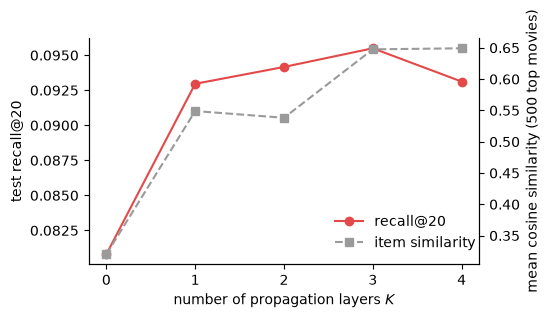

In [15]:
layer_sweep = {}
for K in [0, 1, 2, 3, 4]:
    set_seed(0)
    m = LightGCN(A_HAT, layers=K)
    train_recommender(m, evaluator=None, name=f'LightGCN K={K}', verbose=False)
    with torch.no_grad():
        r = EVAL_TEST(m.score_all)
        _, I_emb = m.propagate()
        e = F.normalize(I_emb[torch.tensor(order[:500].copy(), device=device)], dim=1)
        sim = (e @ e.T).fill_diagonal_(0).sum() / (500 * 499)   # mean cosine similarity of the 500 most popular movies
    layer_sweep[K] = (r['recall@20'], r['ndcg@20'], sim.item())
    print(f'K = {K}: test recall@20 {r["recall@20"]:.4f} | ndcg@20 {r["ndcg@20"]:.4f} | '
          f'mean cosine similarity between items {sim:.3f}')

fig, ax = plt.subplots(figsize=(5.6, 3))
ax.plot(list(layer_sweep), [v[0] for v in layer_sweep.values()], 'o-', color=COLORS['LightGCN'], label='recall@20')
ax.set(xlabel='number of propagation layers $K$', ylabel='test recall@20', xticks=list(layer_sweep))
ax2 = ax.twinx()
ax2.plot(list(layer_sweep), [v[2] for v in layer_sweep.values()], 's--', color=COLORS['Popularity'], label='item similarity')
ax2.set_ylabel('mean cosine similarity (500 top movies)')
ax.spines[['top']].set_visible(False); ax2.spines[['top']].set_visible(False)
fig.legend(loc='lower right', bbox_to_anchor=(0.88, 0.2), frameon=False)
plt.tight_layout(); plt.show()

# 5. KGAT: adding a knowledge graph

## 5.1. The collaborative knowledge graph

The promise and the difficulty of a KG: it relates items that no user ever watched together, which is exactly what a sparse interaction graph cannot do, but we have to decide how to combine the two graphs. KGAT's answer is to merge them into one graph: the user-item interactions become triples $(u, \texttt{interact}, i)$ and are stored next to the KG triples $(i, r, e)$.

We build the KG from the HetRec side information: director, the three top-billed actors, genres, country and decade of every movie. 

We keep an entity only if it is attached to at least two movies — an actor who appears in a single film can carry no collaborative signal.

In [16]:
def build_knowledge_graph(min_entity_degree=2):
    item_of = {m: k for k, m in enumerate(ITEM_IDS)}
    triples = collections.defaultdict(list)                    # relation -> [(item, entity name)]

    _, rows = read_table('movie_directors.dat')
    for r in rows:
        if int(r[0]) in item_of: triples['directed_by'].append((item_of[int(r[0])], 'director:' + r[1]))

    _, rows = read_table('movie_actors.dat')
    billing = collections.defaultdict(list)
    for r in rows:
        if int(r[0]) in item_of and r[3].strip().isdigit():
            billing[item_of[int(r[0])]].append((int(r[3]), r[1]))
    for it, lst in billing.items():
        for _, actor in sorted(lst)[:3]:                       # ★ KEY: only the 3 top-billed actors, else the KG explodes
            triples['starring'].append((it, 'actor:' + actor))

    _, rows = read_table('movie_genres.dat')
    for r in rows:
        if int(r[0]) in item_of: triples['has_genre'].append((item_of[int(r[0])], 'genre:' + r[1]))

    _, rows = read_table('movie_countries.dat')
    for r in rows:
        if int(r[0]) in item_of and r[1].strip(): triples['from_country'].append((item_of[int(r[0])], 'country:' + r[1]))

    _, rows = read_table('movies.dat')
    for r in rows:
        if int(r[0]) in item_of and r[5].strip().isdigit():
            triples['released_in'].append((item_of[int(r[0])], f'decade:{int(r[5]) // 10 * 10}s'))

    count = collections.Counter(e for lst in triples.values() for _, e in lst)
    entities = sorted(e for e, c in count.items() if c >= min_entity_degree)
    entity_of = {e: k for k, e in enumerate(entities)}
    rel_names = list(triples)
    h, r, t = [], [], []
    for k, rel in enumerate(rel_names):
        for it, e in triples[rel]:
            if e in entity_of:
                h.append(it); r.append(k); t.append(entity_of[e])
    return np.array(h), np.array(r), np.array(t), rel_names, entities

KG_H, KG_R, KG_T, REL_NAMES, ENTITIES = build_knowledge_graph()
N_ENT = len(ENTITIES)
print(f'{len(KG_H):,} KG triples over {N_ENT:,} entities and {len(REL_NAMES)} relations')
for k, name in enumerate(REL_NAMES):
    print(f'  {name:<14} {int((KG_R == k).sum()):>6,} triples | '
          f'{len(np.unique(KG_T[KG_R == k])):>5,} entities | example: {ENTITIES[KG_T[KG_R == k][0]]}')
print(f'\nmovies with at least one KG triple: {len(np.unique(KG_H)):,} of {N_ITEMS:,}')

40,202 KG triples over 3,501 entities and 5 relations
  directed_by     4,309 triples |   998 entities | example: director:john_lasseter
  starring       12,086 triples | 2,428 entities | example: actor:tom_hanks
  has_genre      12,571 triples |    19 entities | example: genre:Adventure
  from_country    5,611 triples |    45 entities | example: country:USA
  released_in     5,625 triples |    11 entities | example: decade:1990s

movies with at least one KG triple: 5,626 of 5,626


## 5.2. Attention over $(h, r, t)$

KGAT scores every triple in the merged graph with the TransR,

$$\pi(h, r, t) = (\mathbf W_r \mathbf e_t)^\top \tanh(\mathbf W_r \mathbf e_h + \mathbf e_r),$$

normalised with a softmax over the triples that leave $h$. So a movie attends more to the entities that explain it best, and a user attends more to the movies that best predict their taste. 

The embeddings are then propagated with the bi-interaction aggregator and the layers are concatenated.

Two losses are trained alternately: the BPR loss on the recommendation, and a TransR loss that keeps $\mathbf e_h + \mathbf e_r \approx \mathbf e_t$ for the real triples, which is what makes $\pi$ meaningful.

In [17]:
class KGAT(nn.Module):
    """Nodes: users [0, N_USERS), items [N_USERS, N_USERS+N_ITEMS), KG entities after them."""
    def __init__(self, n_relations, dims=(64, 32, 16), relation_dim=64, dropout=0.1):
        super().__init__()
        d = dims[0]
        self.N = N_USERS + N_ITEMS + N_ENT
        self.emb = nn.Embedding(self.N, d); nn.init.xavier_uniform_(self.emb.weight)
        self.rel_emb = nn.Embedding(n_relations, relation_dim); nn.init.xavier_uniform_(self.rel_emb.weight)
        self.W_r = nn.Parameter(torch.empty(n_relations, d, relation_dim)); nn.init.xavier_uniform_(self.W_r)
        self.W1 = nn.ModuleList([nn.Linear(a, b) for a, b in zip(dims[:-1], dims[1:])])
        self.W2 = nn.ModuleList([nn.Linear(a, b) for a, b in zip(dims[:-1], dims[1:])])
        self.dropout, self.A = dropout, None

    def ego(self, users, items):
        return self.emb.weight[users], self.emb.weight[N_USERS + items]

    @torch.no_grad()
    def update_attention(self, h, r, t):
        """pi(h, r, t), softmax-normalised over the triples with the same head."""
        e = self.emb.weight
        score = torch.empty(len(h), device=device)
        for k in range(self.W_r.size(0)):                       # one projection matrix per relation
            m = r == k
            if m.any():
                W = self.W_r[k]
                score[m] = ((e[t[m]] @ W) * torch.tanh(e[h[m]] @ W + self.rel_emb.weight[k])).sum(1)
        top = torch.full((self.N,), -1e9, device=device).scatter_reduce(0, h, score, 'amax')
        ex = torch.exp(score - top[h])                          # ★ KEY: softmax over the out-triples of each head
        den = torch.zeros(self.N, device=device).index_add_(0, h, ex)
        self.A = torch.sparse_coo_tensor(torch.stack([h, t]), ex / den[h], (self.N, self.N)).coalesce()

    def propagate(self):
        e = self.emb.weight
        out = [e]
        for W1, W2 in zip(self.W1, self.W2):
            side = torch.sparse.mm(self.A, e)
            e = F.leaky_relu(W1(e + side), 0.2) + F.leaky_relu(W2(e * side), 0.2)   # bi-interaction aggregator
            e = F.dropout(e, self.dropout, self.training)
            out.append(F.normalize(e, dim=1))
        e = torch.cat(out, dim=1)
        return e[:N_USERS], e[N_USERS:N_USERS + N_ITEMS]

    def score_all(self, users):
        U_emb, I_emb = self.propagate()
        return U_emb[users] @ I_emb.T

    def transr_loss(self, h, r, t, t_neg):
        e = self.emb.weight
        W = self.W_r[r]; e_r = self.rel_emb(r)
        proj = lambda x: torch.bmm(e[x].unsqueeze(1), W).squeeze(1)
        e_h, e_t, e_n = proj(h), proj(t), proj(t_neg)
        pos = (e_h + e_r - e_t).pow(2).sum(1)
        neg = (e_h + e_r - e_n).pow(2).sum(1)
        return -F.logsigmoid(neg - pos).mean()                  # ★ KEY: real triples must fit e_h + e_r ~ e_t

In [18]:
# the merged graph: interactions (both directions) + KG triples (both directions)
R_KG = len(REL_NAMES)
CKG_H = torch.tensor(np.r_[U[TRAIN], N_USERS + I[TRAIN], N_USERS + KG_H, N_USERS + N_ITEMS + KG_T], device=device)
CKG_T = torch.tensor(np.r_[N_USERS + I[TRAIN], U[TRAIN], N_USERS + N_ITEMS + KG_T, N_USERS + KG_H], device=device)
CKG_R = torch.tensor(np.r_[np.zeros(TRAIN.sum()), np.full(TRAIN.sum(), R_KG + 1),
                           KG_R + 1, KG_R + R_KG + 2].astype(np.int64), device=device)
KG_ONLY = (CKG_R != 0) & (CKG_R != R_KG + 1)
print(f'collaborative knowledge graph: {len(CKG_H):,} triples, {2 * R_KG + 2} relations '
      f'(interact, {R_KG} KG relations, and their inverses)')

def train_kgat(model, epochs=40, lr=5e-3, reg=1e-4, batch_size=4096, evaluator=None, eval_every=10):
    model = model.to(device)
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    kg_h, kg_r, kg_t = CKG_H[KG_ONLY], CKG_R[KG_ONLY], CKG_T[KG_ONLY]
    model.update_attention(CKG_H, CKG_R, CKG_T)
    t0 = time.time()
    for epoch in range(1, epochs + 1):
        model.train()
        perm = torch.randperm(len(TRAIN_U), device=device)                      # (1) recommendation loss
        for s in range(0, len(perm), batch_size):
            idx = perm[s:s + batch_size]
            users, pos = TRAIN_U[idx], TRAIN_I[idx]
            neg = sample_negatives(users)
            U_emb, I_emb = model.propagate()
            loss = bpr_loss((U_emb[users] * I_emb[pos]).sum(1), (U_emb[users] * I_emb[neg]).sum(1))
            e_u, e_i = model.ego(users, torch.cat([pos, neg]))
            loss = loss + reg * (e_u.pow(2).sum() + e_i.pow(2).sum()) / (2 * len(idx))
            opt.zero_grad(); loss.backward(); opt.step()
        perm = torch.randperm(len(kg_h), device=device)                         # (2) knowledge-graph loss
        for s in range(0, len(perm), batch_size):
            idx = perm[s:s + batch_size]
            t_neg = torch.randint(N_USERS + N_ITEMS, model.N, (len(idx),), device=device)
            loss = model.transr_loss(kg_h[idx], kg_r[idx], kg_t[idx], t_neg)
            opt.zero_grad(); loss.backward(); opt.step()
        model.update_attention(CKG_H, CKG_R, CKG_T)                             # (3) refresh the attention
        if evaluator is not None and epoch % eval_every == 0:
            model.eval()
            with torch.no_grad():
                print(f'  epoch {epoch:>3} | val recall@20 {evaluator(model.score_all)["recall@20"]:.4f}')
    model.eval()
    return dict(time=time.time() - t0, params=n_params(model))

set_seed(0)
kgat = KGAT(2 * R_KG + 2)
info = train_kgat(kgat, evaluator=EVAL_VAL)
with torch.no_grad():
    record('KGAT', kgat.score_all, family='KGAT', **info)

collaborative knowledge graph: 671,818 triples, 12 relations (interact, 5 KG relations, and their inverses)
  epoch  10 | val recall@20 0.1014
  epoch  20 | val recall@20 0.1081
  epoch  30 | val recall@20 0.1033
  epoch  40 | val recall@20 0.1016
KGAT                         test recall@20 0.0815 | ndcg@20 0.0692 | recall@10 0.0492


## 5.3. What did the attention learn, and for whom does the KG help?

Two questions worth asking of any KG model. 

First, which relations does the attention use: we average $\pi$ over all triples of each relation. 

Second — the one that matters for a recommender — which users benefit: the KG should help where the interaction graph is thin, so we split the test users by how many training interactions they have and compare KGAT with LightGCN group by group.

In [19]:
with torch.no_grad():
    # the un-normalised score pi(h, r, t), averaged per relation
    e = kgat.emb.weight
    mean_att = {}
    for k in range(2 * R_KG + 2):
        m = CKG_R == k
        if not m.any(): continue
        W = kgat.W_r[k]
        s = ((e[CKG_T[m]] @ W) * torch.tanh(e[CKG_H[m]] @ W + kgat.rel_emb.weight[k])).sum(1)
        name = (['interact'] + REL_NAMES + ['interacted_by'] + [f'{r}$^{{-1}}$' for r in REL_NAMES])[k]
        mean_att[name] = s.mean().item()
print('mean attention score pi(h, r, t) per relation (before the softmax):')
for name, v in sorted(mean_att.items(), key=lambda kv: -kv[1]):
    print(f'  {name:<22} {v:+.3f}')

# who benefits from the knowledge graph?
deg_train = np.bincount(U[TRAIN], minlength=N_USERS)
groups = [(0, 20), (20, 50), (50, 150), (150, 10 ** 9)]
with torch.no_grad():
    per_user = {name: EVAL_TEST(m.score_all, per_user=True)
                for name, m in [('LightGCN (3 layers)', lightgcn), ('KGAT', kgat)]}
test_users = EVAL_TEST.users.cpu().numpy()
print(f'\n{"users with":<22}{"n":>6}{"LightGCN":>12}{"KGAT":>10}')
for lo, hi in groups:
    m = (deg_train[test_users] >= lo) & (deg_train[test_users] < hi)
    a = per_user['LightGCN (3 layers)']['recall@20'][torch.tensor(m, device=device)].mean().item()
    b = per_user['KGAT']['recall@20'][torch.tensor(m, device=device)].mean().item()
    label = f'{lo}-{hi if hi < 10 ** 9 else ""} interactions'
    print(f'{label:<22}{m.sum():>6}{a:>12.4f}{b:>10.4f}')

mean attention score pi(h, r, t) per relation (before the softmax):
  directed_by            +7.223
  released_in            +5.407
  starring               +5.242
  from_country           +4.389
  has_genre              +4.344
  released_in$^{-1}$     +3.524
  starring$^{-1}$        +1.950
  directed_by$^{-1}$     +1.918
  from_country$^{-1}$    +1.769
  has_genre$^{-1}$       +1.149
  interact               +0.167
  interacted_by          +0.141

users with                 n    LightGCN      KGAT
0-20 interactions        201      0.1567    0.1468
20-50 interactions       375      0.1701    0.1359
50-150 interactions      830      0.0880    0.0776
150- interactions        696      0.0465    0.0380


# 6. ContextGNN: beyond two-tower recommendation

## 6.1. The problem with a single ranking

Everything above is a two-tower model: a user vector, an item vector, one inner product. 

Its weakness — the item representation is pair-agnostic, the same vector for everybody, so the model cannot express "this user keeps going back to this place". 

For a recommender, that is the difference between predicting a repeat visit and predicting an exploration.

The MovieLens data above cannot show this: nobody likes the same film twice. We therefore switch to a dataset where repetition is the dominant signal — **Gowalla check-ins** (Cho et al., KDD 2011), the location-based social network. We use every check-in inside Austin, Texas between June and October 2010, 10-core filtered, plus the friendship edges between those users.

The task: at a snapshot time $t$, look at everything that happened before $t$ and predict the places each user will check into during the next 21 days.

In [20]:
GOWALLA = f'{DATA}/gowalla'
rows = [l.rstrip('\n').split('\t') for l in open(f'{GOWALLA}/austin_checkins.txt')][1:]
GU_IDS, GU = np.unique([int(r[0]) for r in rows], return_inverse=True)
GL_IDS, GL = np.unique([int(r[2]) for r in rows], return_inverse=True)
T0 = datetime.datetime(2010, 6, 1, tzinfo=datetime.timezone.utc)
GDAY = np.array([(datetime.datetime.fromisoformat(r[1].replace('Z', '+00:00')) - T0).total_seconds() / 86400
                 for r in rows])
N_GU, N_GL = len(GU_IDS), len(GL_IDS)
LATLON = np.array([[float(x) for x in l.split('\t')[1:]] for l in open(f'{GOWALLA}/austin_locations.txt').readlines()[1:]])
FRIENDS = np.array([[int(x) for x in l.split('\t')] for l in open(f'{GOWALLA}/austin_friends.txt').readlines()[1:]])

def day_of(s):
    return (datetime.datetime.fromisoformat(s + 'T00:00:00+00:00') - T0).total_seconds() / 86400

print(f'{len(rows):,} check-ins | {N_GU:,} users | {N_GL:,} locations | {len(FRIENDS):,} friendships')
print(f'a user checks in {len(rows) / N_GU:.0f} times on average, at {len(set(zip(GU, GL))) / N_GU:.0f} distinct places')
visits = collections.Counter(zip(GU.tolist(), GL.tolist()))
print(f'{np.mean([v > 1 for v in visits.values()]):.1%} of the (user, place) pairs are visited more than once '
      f'-- this is the rich past interactions regime')

127,029 check-ins | 2,357 users | 3,150 locations | 9,812 friendships
a user checks in 54 times on average, at 32 distinct places
21.5% of the (user, place) pairs are visited more than once -- this is the rich past interactions regime


In [21]:
WINDOW = 21                     # days of the prediction horizon

class Snapshot:
    """Everything before t is history (the graph); the next WINDOW days are the targets."""
    def __init__(self, t, window=WINDOW):
        past = GDAY < t
        pair = GU[past] * N_GL + GL[past]
        key, inv, count = np.unique(pair, return_inverse=True, return_counts=True)
        last = np.full(len(key), -1e9); np.maximum.at(last, inv, GDAY[past])
        self.hu, self.hi = key // N_GL, key % N_GL                 # one history edge per (user, place)
        total = np.bincount(self.hu, weights=count, minlength=N_GU)
        self.feat = np.stack([np.log1p(count), count / total[self.hu],
                              np.exp(-(t - last)), np.exp(-(t - last) / 7), np.exp(-(t - last) / 30)],
                             1).astype(np.float32)                 # ★ KEY: edge features = how often, how recently
        self.count = count
        order = np.argsort(self.hu, kind='stable')
        self.u_ptr = np.r_[0, np.cumsum(np.bincount(self.hu, minlength=N_GU))]
        self.u_nbr, self.u_eid = self.hi[order], order
        order = np.argsort(self.hi, kind='stable')
        self.i_ptr = np.r_[0, np.cumsum(np.bincount(self.hi, minlength=N_GL))]
        self.i_nbr, self.i_eid = self.hu[order], order
        future = (GDAY >= t) & (GDAY < t + window)
        tp = np.unique(GU[future] * N_GL + GL[future])
        tu, ti = tp // N_GL, tp % N_GL
        warm = np.bincount(self.hu, minlength=N_GU) > 0
        self.tu, self.ti = tu[warm[tu]], ti[warm[tu]]              # users with no history cannot be scored
        self.users = np.unique(self.tu)
        seen = set(key.tolist())
        self.repeat = np.array([u * N_GL + i in seen for u, i in zip(self.tu, self.ti)])
        recent = (GDAY < t) & (GDAY >= t - window)
        self.pop = np.bincount(GL[recent], minlength=N_GL).astype(np.float32)
        self.user_x = np.stack([np.log1p(np.bincount(GU[past], minlength=N_GU)),
                                np.log1p(np.bincount(self.hu, minlength=N_GU))], 1).astype(np.float32)
        self.item_x = np.stack([np.log1p(self.pop), np.log1p(np.bincount(self.hi, minlength=N_GL))], 1).astype(np.float32)
        self.t = t
        for k in ['u_ptr', 'u_nbr', 'u_eid', 'i_ptr', 'i_nbr', 'i_eid', 'hu', 'hi']:
            setattr(self, 'T_' + k, torch.tensor(getattr(self, k), device=device))
        for k in ['feat', 'user_x', 'item_x']:
            setattr(self, 'T_' + k, torch.tensor(getattr(self, k), device=device))

TRAIN_SNAPS = [f'train{k}' for k in range(7)]
SNAPSHOT_TIME = {f'train{k}': day_of('2010-07-03') + 7 * k for k in range(7)}
SNAPSHOT_TIME |= {'val': day_of('2010-09-11'), 'test': day_of('2010-10-02')}
SNAP = {k: Snapshot(t) for k, t in SNAPSHOT_TIME.items()}

print(f'{"snapshot":<10}{"history edges":>15}{"users":>8}{"targets":>9}{"repeat share":>14}')
for k in ['train0', 'train6', 'val', 'test']:
    s = SNAP[k]
    print(f'{k:<10}{len(s.hu):>15,}{len(s.users):>8,}{len(s.tu):>9,}{s.repeat.mean():>13.1%}')

snapshot    history edges   users  targets  repeat share
train0             14,017   1,021   10,301        21.5%
train6             34,282   1,380   13,308        29.3%
val                50,472   1,539   14,713        31.2%
test               62,592   1,625   14,662        32.9%


A third of what a user will do in the next three weeks is a place they have already been to. 

The local items — the ones the user has rich past interactions with — against the distant/exploratory ones.

Two trivial predictors already tell us what each regime is worth. 

Popularity ranks by the check-ins of the last 21 days and can only ever find new places.

Go back where you went ranks the user's own history by visit count and can only ever find repeats.

In [22]:
def evaluate_ctx(snap, score_fn, Ks=(10, 20), batch=512):
    """Recall@K, split into the repeated and the new part of the targets."""
    users = torch.tensor(snap.users, device=device)
    target = torch.zeros(len(users), N_GL, dtype=torch.bool, device=device)
    pos = torch.searchsorted(users, torch.tensor(snap.tu, device=device))
    target[pos, torch.tensor(snap.ti, device=device)] = True
    rep = torch.zeros_like(target)
    rep[pos[torch.tensor(snap.repeat, device=device)], torch.tensor(snap.ti[snap.repeat], device=device)] = True
    new = target & ~rep
    scores = torch.cat([score_fn(users[k:k + batch]) for k in range(0, len(users), batch)])
    out = {}
    for K in Ks:
        top = scores.topk(K, 1).indices
        for name, tgt in [('recall', target), ('repeat', rep), ('new', new)]:
            hit = tgt.gather(1, top).float().sum(1)
            m = tgt.sum(1) > 0
            out[f'{name}@{K}'] = (hit[m] / tgt.sum(1)[m].float()).mean().item()
    return out

def popularity_scores(snap, users):
    return torch.tensor(snap.pop, device=device)[None].expand(len(users), -1)

def history_scores(snap, users):
    counts = torch.zeros(N_GU, N_GL, device=device)
    counts[snap.T_hu, snap.T_hi] = torch.tensor(snap.count, dtype=torch.float32, device=device)
    return counts[users]

CTX_RESULTS = {}
def record_ctx(name, score_fn):
    CTX_RESULTS[name] = evaluate_ctx(SNAP['test'], lambda ub: score_fn(SNAP['test'], ub))
    r = CTX_RESULTS[name]
    print(f'{name:<34} recall@20 {r["recall@20"]:.4f} | repeated {r["repeat@20"]:.4f} | new {r["new@20"]:.4f}')
    return r

record_ctx('Popularity (last 21 days)', popularity_scores)
record_ctx('Go back where you went', history_scores)

Popularity (last 21 days)          recall@20 0.0891 | repeated 0.1382 | new 0.0650
Go back where you went             recall@20 0.2938 | repeated 0.8550 | new 0.0057


{'recall@10': 0.2428072690963745,
 'repeat@10': 0.709311842918396,
 'new@10': 0.0013087330153211951,
 'recall@20': 0.29381412267684937,
 'repeat@20': 0.85499107837677,
 'new@20': 0.0056600612588226795}

## 6.2. Sampling a user-specific subgraph

ContextGNN builds a $k$-hop subgraph around one user, marks that user with a learnable `INDICATOR` embedding, runs a GNN on it, and reads out the item representations inside that subgraph. 

Because the subgraph and the indicator are different for every seed user, the item representation $\mathbf h_w^{(2)}$ now depends on the user — that is the "pair-wise" part.

We sample 2 hops: user $\to$ all their places $\to$ up to 10 other users per place.

In [23]:
def sample_neighbours(ptr, nbr, eid, nodes, fanout):
    """For every node, all of its neighbours (fanout=None) or `fanout` distinct random ones."""
    deg = ptr[nodes + 1] - ptr[nodes]
    if fanout is None:
        src = torch.repeat_interleave(torch.arange(len(nodes), device=device), deg)
        offset = torch.arange(int(deg.sum()), device=device) - torch.repeat_interleave(torch.cumsum(deg, 0) - deg, deg)
    else:
        r = torch.rand(len(nodes), int(deg.max().clamp(min=1)), device=device)
        r = r.masked_fill(torch.arange(r.size(1), device=device)[None] >= deg[:, None], 2.0)
        offset = r.argsort(1)[:, :fanout]
        valid = torch.gather(r, 1, offset) < 2.0
        src = torch.arange(len(nodes), device=device)[:, None].expand_as(offset)[valid]
        offset = offset[valid]
    pos = ptr[nodes][src] + offset
    return src, nbr[pos], eid[pos]

class SubgraphBatch:
    """Disjoint union of the sampled subgraphs of a batch of seed users."""
    def __init__(self, snap, seeds, fanouts=(None, 10)):
        B = len(seeds)
        users, user_b = [seeds], [torch.arange(B, device=device)]
        items, item_b, edges = [], [], []
        frontier, fb, is_user = seeds, torch.arange(B, device=device), True
        for fanout in fanouts:
            if is_user:
                src, nxt, eid = sample_neighbours(snap.T_u_ptr, snap.T_u_nbr, snap.T_u_eid, frontier, fanout)
                b = fb[src]; edges.append((b, frontier[src], nxt, eid)); items.append(nxt); item_b.append(b)
            else:
                src, nxt, eid = sample_neighbours(snap.T_i_ptr, snap.T_i_nbr, snap.T_i_eid, frontier, fanout)
                b = fb[src]; edges.append((b, nxt, frontier[src], eid)); users.append(nxt); user_b.append(b)
            frontier, fb, is_user = nxt, b, not is_user
        # a node is identified by (subgraph, id): the same user in two subgraphs is two different nodes
        ukey = torch.cat(user_b) * N_GU + torch.cat(users)
        ikey = torch.cat(item_b) * N_GL + torch.cat(items)
        self.ukeys, uinv = torch.unique(ukey, return_inverse=True)
        self.ikeys = torch.unique(ikey)
        self.user_id, self.user_b = self.ukeys % N_GU, self.ukeys // N_GU
        self.item_id, self.item_b = self.ikeys % N_GL, self.ikeys // N_GL
        self.seed_local = uinv[:B]                                    # where each seed user sits in the union
        eb = torch.cat([e[0] for e in edges]); eu = torch.cat([e[1] for e in edges])
        ei = torch.cat([e[2] for e in edges]); ee = torch.cat([e[3] for e in edges])
        eu_l = torch.searchsorted(self.ukeys, eb * N_GU + eu)
        ei_l = torch.searchsorted(self.ikeys, eb * N_GL + ei)
        key = eu_l * len(self.ikeys) + ei_l
        uniq, inv = torch.unique(key, return_inverse=True)             # keep one copy of every edge
        idx = torch.full((len(uniq),), len(key), device=device).scatter_reduce(0, inv, torch.arange(len(key), device=device), 'amin')
        self.eu, self.ei, self.efeat = eu_l[idx], ei_l[idx], snap.T_feat[ee[idx]]
        self.ux, self.ix = snap.T_user_x[self.user_id], snap.T_item_x[self.item_id]
        self.B = B

g = SubgraphBatch(SNAP['test'], torch.tensor(SNAP['test'].users[:128], device=device))
print(f'a batch of 128 user subgraphs: {len(g.ukeys):,} user nodes, {len(g.ikeys):,} place nodes, {len(g.eu):,} edges')

a batch of 128 user subgraphs: 47,761 user nodes, 7,738 place nodes, 78,641 edges


## 6.3. The three models

Everything below shares one GNN; only the decoder changes.

* Two-tower: the GNN produces $\mathbf h_v$ for the seed user, items are scored with a shallow embedding table, $\text{score}(v, w) = \mathbf h_v^\top \mathbf w_w$. Every item in the catalogue gets a score. No indicator.

* Pair-wise: the seed user is marked with `INDICATOR`, and an item inside the subgraph is scored with its contextual representation, $\text{score}(v, w) = \mathbf h_v^\top \mathbf h_w^{(2)}$. Items outside the subgraph cannot be scored at all.

* ContextGNN: both and fused. The pair-wise score is used for the items in the subgraph, the two-tower score for the rest, and a learned user-specific fusion score $\text{MLP}_\theta(\mathbf h_v)$ shifts one against the other so the two rankings can be merged into one.

In [24]:
class HeteroSAGE(nn.Module):
    """One message-passing layer on the bipartite subgraph; messages carry the edge features."""
    def __init__(self, dim, edge_dim=5):
        super().__init__()
        self.msg_u = nn.Sequential(nn.Linear(dim + edge_dim, dim), nn.ReLU(), nn.Linear(dim, dim))
        self.msg_i = nn.Sequential(nn.Linear(dim + edge_dim, dim), nn.ReLU(), nn.Linear(dim, dim))
        self.self_u, self.self_i = nn.Linear(dim, dim), nn.Linear(dim, dim)
        self.norm_u, self.norm_i = nn.LayerNorm(dim), nn.LayerNorm(dim)

    def forward(self, hu, hi, eu, ei, ef):
        m = self.msg_u(torch.cat([hi[ei], ef], 1))
        agg_u = torch.zeros_like(hu).index_add_(0, eu, m) / torch.bincount(eu, minlength=len(hu)).clamp(min=1)[:, None]
        m = self.msg_i(torch.cat([hu[eu], ef], 1))
        agg_i = torch.zeros_like(hi).index_add_(0, ei, m) / torch.bincount(ei, minlength=len(hi)).clamp(min=1)[:, None]
        return F.relu(self.norm_u(self.self_u(hu) + agg_u)), F.relu(self.norm_i(self.self_i(hi) + agg_i))

class ContextGNN(nn.Module):
    def __init__(self, dim=64, layers=2, mode='context', dropout=0.1):
        super().__init__()
        self.user_in, self.item_in = nn.Linear(2, dim), nn.Linear(2, dim)
        self.item_emb = nn.Embedding(N_GL, dim)                   # the shallow item tower w_w
        nn.init.normal_(self.item_emb.weight, std=0.1)
        self.indicator = nn.Parameter(torch.randn(dim) * 0.1)     # ★ KEY: INDICATOR marks the seed user
        self.convs = nn.ModuleList([HeteroSAGE(dim) for _ in range(layers)])
        self.fusion = nn.Sequential(nn.Linear(dim, dim), nn.ReLU(), nn.Linear(dim, 1))
        self.mode, self.dropout = mode, dropout

    def forward(self, g):
        is_seed = torch.zeros(len(g.ukeys), dtype=torch.bool, device=device)
        is_seed[g.seed_local] = True
        hu = self.user_in(g.ux)
        if self.mode != 'two_tower':
            hu = hu + is_seed[:, None] * self.indicator
        hi = self.item_emb(g.item_id) + self.item_in(g.ix)
        for conv in self.convs:
            hu, hi = conv(hu, hi, g.eu, g.ei, g.efeat)
            hu, hi = F.dropout(hu, self.dropout, self.training), F.dropout(hi, self.dropout, self.training)
        h_seed = hu[g.seed_local]                                                  # [B, dim]
        two_tower = h_seed @ self.item_emb.weight.T                                # [B, N_GL], pair-agnostic
        if self.mode == 'two_tower':
            return two_tower
        local = is_seed[g.eu]                                                      # the seed's own places = hop-1 items
        li = g.ei[local]; lb = g.item_b[li]
        pair_wise = (h_seed[lb] * hi[li]).sum(1)                                   # ★ KEY: item repr. depends on the user
        if self.mode == 'pair_wise':
            out = torch.full_like(two_tower, -1e4)
            out[lb, g.item_id[li]] = pair_wise
            return out
        out = two_tower.clone()
        out[lb, g.item_id[li]] = pair_wise + self.fusion(h_seed).squeeze(1)[lb]    # ★ KEY: user-specific fusion
        return out

In [25]:
def train_contextgnn(mode, epochs=12, lr=1e-3, batch=128, fanouts=(None, 10), seed=0, verbose=True):
    set_seed(seed)
    model = ContextGNN(mode=mode).to(device)
    opt = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=1e-5)
    targets, position = {}, {}
    for name in TRAIN_SNAPS:                                   # the training targets of every snapshot
        s = SNAP[name]
        pos = {u: k for k, u in enumerate(s.users.tolist())}
        y = torch.zeros(len(s.users), N_GL, device=device)
        y[torch.tensor([pos[u] for u in s.tu], device=device), torch.tensor(s.ti, device=device)] = 1
        targets[name], position[name] = y, pos
    best, t0 = (-1, None), time.time()
    for epoch in range(1, epochs + 1):
        model.train()
        for name in np.random.permutation(TRAIN_SNAPS):
            users = SNAP[name].users.copy(); np.random.shuffle(users)
            for k in range(0, len(users), batch):
                ub = torch.tensor(users[k:k + batch], device=device)
                scores = model(SubgraphBatch(SNAP[name], ub, fanouts))
                y = targets[name][[position[name][u] for u in ub.tolist()]]
                loss = -(F.log_softmax(scores, 1) * y).sum(1).div(y.sum(1)).mean()   # ★ KEY: softmax over the catalogue
                opt.zero_grad(); loss.backward(); opt.step()
        model.eval()
        with torch.no_grad():
            r = evaluate_ctx(SNAP['val'], lambda ub: model(SubgraphBatch(SNAP['val'], ub, fanouts)))
        if verbose and epoch % 3 == 0:
            print(f'  epoch {epoch:>2} | val recall@20 {r["recall@20"]:.4f} '
                  f'(repeated {r["repeat@20"]:.3f}, new {r["new@20"]:.3f})')
        if r['recall@20'] > best[0]:
            best = (r['recall@20'], {k: v.detach().clone() for k, v in model.state_dict().items()})
    model.load_state_dict(best[1])                              # ★ KEY: early stopping on the validation snapshot
    model.eval()
    print(f'  trained {mode} in {time.time() - t0:.0f}s, {n_params(model):,} parameters')
    return model

CTX_MODELS = {}
for mode, label in [('two_tower', 'Two-tower'), ('pair_wise', 'Pair-wise only'), ('context', 'ContextGNN (fused)')]:
    print(f'\n{label}:')
    CTX_MODELS[mode] = train_contextgnn(mode)
    with torch.no_grad():
        record_ctx(label, lambda s, ub, m=CTX_MODELS[mode]: m(SubgraphBatch(s, ub)))


Two-tower:
  epoch  3 | val recall@20 0.0995 (repeated 0.137, new 0.076)
  epoch  6 | val recall@20 0.0991 (repeated 0.131, new 0.078)
  epoch  9 | val recall@20 0.0960 (repeated 0.126, new 0.076)
  epoch 12 | val recall@20 0.1002 (repeated 0.135, new 0.076)
  trained two_tower in 22s, 257,985 parameters
Two-tower                          recall@20 0.0957 | repeated 0.1393 | new 0.0721

Pair-wise only:
  epoch  3 | val recall@20 0.2326 (repeated 0.733, new 0.011)
  epoch  6 | val recall@20 0.2326 (repeated 0.733, new 0.011)
  epoch  9 | val recall@20 0.2326 (repeated 0.733, new 0.011)
  epoch 12 | val recall@20 0.2326 (repeated 0.733, new 0.011)
  trained pair_wise in 20s, 257,985 parameters
Pair-wise only                     recall@20 0.2456 | repeated 0.7195 | new 0.0057

ContextGNN (fused):
  epoch  3 | val recall@20 0.2859 (repeated 0.820, new 0.041)
  epoch  6 | val recall@20 0.2797 (repeated 0.813, new 0.038)
  epoch  9 | val recall@20 0.2835 (repeated 0.820, new 0.038)
  epoch 

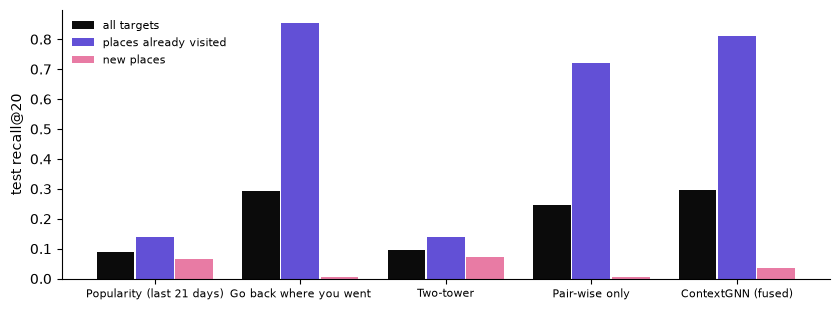

In [26]:
fig, ax = plt.subplots(figsize=(8.5, 3.2))
names = list(CTX_RESULTS)
x = np.arange(len(names))
for k, (key, label, col) in enumerate([('recall@20', 'all targets', COLORS['Data']),
                                       ('repeat@20', 'places already visited', COLORS['ContextGNN']),
                                       ('new@20', 'new places', COLORS['Two-tower'])]):
    ax.bar(x + (k - 1) * 0.27, [CTX_RESULTS[n][key] for n in names], 0.26, label=label, color=col)
ax.set_xticks(x); ax.set_xticklabels(names, fontsize=8)
ax.set_ylabel('test recall@20'); ax.legend(frameon=False, fontsize=8)
ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout(); plt.show()

# Part I: all the models side by side

Every model of Sections 2-5 is trained on the same graph with the same loss, the same optimiser and the same number of epochs; only the encoder changes.

model                     recall@10  recall@20   ndcg@20      params    time
Popularity                   0.0418     0.0719    0.0616           0      0s
MF (binary loss)             0.0412     0.0762    0.0616     494,592     40s
MF (BPR loss)                0.0476     0.0808    0.0689     494,592     41s
NGCF (3 layers)              0.0456     0.0813    0.0665     519,552    100s
LightGCN (3 layers)          0.0585     0.0955    0.0831     494,592     73s
KGAT                         0.0492     0.0815    0.0692     773,792     60s


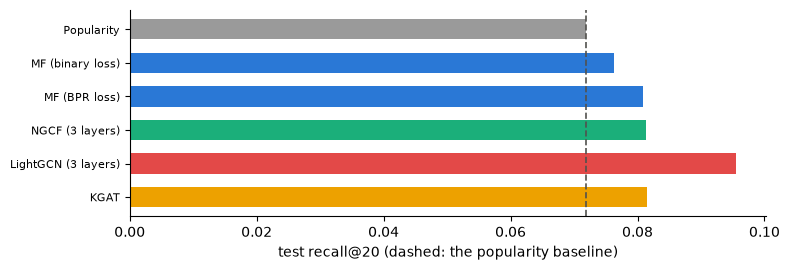

In [27]:
print(f"{'model':<24}{'recall@10':>11}{'recall@20':>11}{'ndcg@20':>10}{'params':>12}{'time':>8}")
for name, r in RESULTS.items():
    print(f"{name:<24}{r['test']['recall@10']:>11.4f}{r['test']['recall@20']:>11.4f}{r['test']['ndcg@20']:>10.4f}"
          f"{r.get('params', 0):>12,}{r.get('time', 0):>7.0f}s")

fig, ax = plt.subplots(figsize=(8, 2.8))
names = list(RESULTS)
ax.barh(range(len(names)), [RESULTS[n]['test']['recall@20'] for n in names],
        color=[COLORS.get(RESULTS[n]['family'], '#9a9a9a') for n in names], height=0.6)
ax.axvline(RESULTS['Popularity']['test']['recall@20'], color='#52514e', ls='--', lw=1.2)
ax.set_yticks(range(len(names))); ax.set_yticklabels(names, fontsize=8); ax.invert_yaxis()
ax.set_xlabel('test recall@20 (dashed: the popularity baseline)')
ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout(); plt.show()

# Part II: GNNs for Molecular Structure Learning

A molecule is a graph whose nodes are atoms and whose edges are bonds. 

Unlike the recommender graph of Part I, this one comes with features everywhere — the element, the charge, the bond order — and with something no other graph in this course has had: the 3-D positions of its nodes, which are what actually determine how a molecule behaves.

First how a molecule is written down and turned into a graph, then property prediction with the GNNs, then what changes when we add coordinates, and finally how to learn without labels.

# 7. From SMILES to a graph

## 7.1. The five rules

There are five ways to write a molecule down. We work with SMILES, because it is what every molecular dataset ships, and because its complete grammar in five rules:

1. atoms and bonds: an element symbol is an atom (`C`, `Na`, `Cl`), lower case means aromatic (`c1ccccc1`); `-` `=` `#` are single, double and triple bonds, and `.` separates disconnected parts;
2. chains: hydrogens are suppressed — `CCO` is ethanol, with 6 implicit H;
3. branches: parentheses, attached to the preceding atom: `CC(=O)C` is acetone;
4. rings: a digit opens a ring and the same digit closes it: `c1ccccc1` is benzene;
5. charges and anything unusual: inside brackets, `[O-]`, `[NH4+]`, `[13C]`.

In [ ]:
ELEMENTS = ['H', 'He', 'Li', 'Be', 'B', 'C', 'N', 'O', 'F', 'Ne', 'Na', 'Mg', 'Al', 'Si', 'P', 'S', 'Cl', 'Ar', 'K',
            'Ca', 'Sc', 'Ti', 'V', 'Cr', 'Mn', 'Fe', 'Co', 'Ni', 'Cu', 'Zn', 'Ga', 'Ge', 'As', 'Se', 'Br', 'Kr', 'Rb',
            'Sr', 'Y', 'Zr', 'Nb', 'Mo', 'Tc', 'Ru', 'Rh', 'Pd', 'Ag', 'Cd', 'In', 'Sn', 'Sb', 'Te', 'I', 'Xe', 'Cs',
            'Ba', 'La', 'Ce', 'Pr', 'Nd', 'Pm', 'Sm', 'Eu', 'Gd', 'Tb', 'Dy', 'Ho', 'Er', 'Tm', 'Yb', 'Lu', 'Hf', 'Ta',
            'W', 'Re', 'Os', 'Ir', 'Pt', 'Au', 'Hg', 'Tl', 'Pb', 'Bi', 'Po', 'At', 'Rn', 'Fr', 'Ra', 'Ac', 'Th', 'Pa', 'U']
ATOMIC_NUMBER = {e: k + 1 for k, e in enumerate(ELEMENTS)}
# the normal valences: how many bonds an atom of this element makes when nothing says otherwise (rule 2)
VALENCE = {'B': (3,), 'C': (4,), 'N': (3, 5), 'O': (2,), 'P': (3, 5), 'S': (2, 4, 6),
           'F': (1,), 'Cl': (1,), 'Br': (1,), 'I': (1,)}
BOND_ORDER = {'-': 1, '=': 2, '#': 3, '$': 4, ':': 1.5, '/': 1, '\\': 1}

TOKEN = re.compile(r'(\[[^\]]+\]|Br|Cl|B|C|N|O|P|S|F|I|b|c|n|o|p|s|\*|\(|\)|\.|=|#|\$|-|\+|:|/|\\|%\d{2}|\d)')
BRACKET = re.compile(r'^\[(\d+)?([A-Z][a-z]?|[a-z][a-z]?|\*)(@{1,2})?(H\d?)?([+-]{1,}\d*)?(:\d+)?\]$')

class SmilesError(ValueError):
    pass

def parse_atom(token):
    """One atom: either a bare symbol (rule 1) or a bracket atom (rule 5)."""
    if token[0] != '[':
        return dict(symbol=token.capitalize(), aromatic=token.islower(), charge=0, h=None, bracket=False, isotope=None)
    m = BRACKET.match(token)
    if not m:
        raise SmilesError(f'bad bracket atom {token}')
    isotope, symbol, _, h, charge, _ = m.groups()
    aromatic = symbol.islower()
    symbol = symbol.capitalize()
    if symbol not in ATOMIC_NUMBER and symbol != '*':
        raise SmilesError(f'unknown element {symbol}')
    n_h = 0 if h is None else (1 if h == 'H' else int(h[1:]))
    q = 0
    if charge:
        q = (1 if charge[0] == '+' else -1) * (int(charge[1:]) if charge[1:].isdigit() else len(charge))
    return dict(symbol=symbol, aromatic=aromatic, charge=q, h=n_h, bracket=True, isotope=isotope)

def parse_smiles(smiles):
    """SMILES string -> (atoms, bonds) following the five rules."""
    tokens = TOKEN.findall(smiles.strip())
    if ''.join(tokens) != smiles.strip():
        raise SmilesError(f'unknown characters in {smiles!r}')
    atoms, bonds = [], []
    previous, branch_stack, open_rings, bond = None, [], {}, None
    for tok in tokens:
        if tok == '(':                                              # rule 3: a branch starts
            branch_stack.append(previous)
        elif tok == ')':                                            # ... and comes back to the same atom
            previous = branch_stack.pop()
        elif tok in BOND_ORDER:
            bond = tok
        elif tok == '.':                                            # rule 1: disconnected structures
            previous = None
        elif tok[0].isdigit() or tok[0] == '%':                     # rule 4: ring opening / closing
            n = int(tok.lstrip('%'))
            if n in open_rings:
                j, b0 = open_rings.pop(n)
                b = bond or b0
                order = BOND_ORDER[b] if b else (1.5 if atoms[previous]['aromatic'] and atoms[j]['aromatic'] else 1)
                bonds.append((j, previous, order))
            else:
                open_rings[n] = (previous, bond)
            bond = None
        else:
            atom = parse_atom(tok)
            atoms.append(atom)
            if previous is not None:
                order = BOND_ORDER[bond] if bond else (1.5 if atom['aromatic'] and atoms[previous]['aromatic'] else 1)
                bonds.append((previous, len(atoms) - 1, order))
            previous, bond = len(atoms) - 1, None
    if open_rings:
        raise SmilesError(f'unclosed ring(s) {sorted(open_rings)}')
    if branch_stack:
        raise SmilesError('unbalanced parenthesis')
    atoms, bonds = merge_explicit_hydrogens(atoms, bonds)
    add_implicit_hydrogens(atoms, bonds)
    return atoms, bonds

def merge_explicit_hydrogens(atoms, bonds):
    # an [H] written as its own atom becomes a hydrogen count on its heavy neighbour (the usual convention)
    drop = set()
    for i, j, _ in bonds:
        for h, heavy in ((i, j), (j, i)):
            if atoms[h]['symbol'] == 'H' and atoms[heavy]['symbol'] != 'H' and not atoms[h]['charge'] and not atoms[h]['isotope']:
                drop.add(h)
                if atoms[heavy]['bracket']:
                    atoms[heavy]['h'] += 1
    if not drop:
        return atoms, bonds
    renumber = {old: new for new, old in enumerate(i for i in range(len(atoms)) if i not in drop)}
    return ([a for i, a in enumerate(atoms) if i not in drop],
            [(renumber[i], renumber[j], o) for i, j, o in bonds if i in renumber and j in renumber])

def add_implicit_hydrogens(atoms, bonds):
    """Rule 2: fill every atom up to its smallest normal valence."""
    order_sum = [0.0] * len(atoms)
    for i, j, o in bonds:
        for k in (i, j):
            order_sum[k] += 1 if o == 1.5 else o                    # ★ KEY: an aromatic bond counts as a single bond...
    for k, a in enumerate(atoms):
        if a['h'] is not None:                                      # bracket atoms state their hydrogens explicitly
            continue
        valences = VALENCE.get(a['symbol'])
        if valences is None:
            raise SmilesError(f"{a['symbol']} has to be written in brackets")
        v = next((v for v in valences if v >= order_sum[k]), None)
        if v is None:
            raise SmilesError(f"valence error: {a['symbol']} with bond order sum {order_sum[k]:g}, allowed {valences}")
        a['h'] = int(max(0, v - order_sum[k] - (1 if a['aromatic'] else 0)))   # ★ KEY: ... plus one for the ring system

for smi, name in [('CCO', 'ethanol (rule 2)'), ('CC(=O)C', 'acetone (rule 3)'), ('c1ccccc1', 'benzene (rule 4)'),
                  ('[Na+].[Cl-]', 'salt (rules 1 and 5)')]:
    atoms, bonds = parse_smiles(smi)
    print(f'{smi:<14} {name:<22} {len(atoms)} heavy atoms, {len(bonds)} bonds, '
          f'H counts {[a["h"] for a in atoms]}')

CCO            ethanol (rule 2)       3 heavy atoms, 2 bonds, H counts [3, 2, 1]
CC(=O)C        acetone (rule 3)       4 heavy atoms, 3 bonds, H counts [3, 0, 0, 3]
c1ccccc1       benzene (rule 4)       6 heavy atoms, 6 bonds, H counts [1, 1, 1, 1, 1, 1]
[Na+].[Cl-]    salt (rules 1 and 5)   2 heavy atoms, 0 bonds, H counts [0, 0]


## 7.2. The molecular graph

With the atoms and the bonds we have the labelled graph: an adjacency matrix whose entries are bond orders, node labels (element, charge, hydrogens, aromaticity) and edge labels (bond order, ring membership).

Two functions below are worth the few lines they cost. 

`formula` sums the atoms up and lets us check a parse against chemistry we can read, and `ring_membership` finds which atoms and bonds lie on a cycle — a bond is on a cycle exactly when it is **not a bridge**, which is Tarjan's classical algorithm and tells us the rings without enumerating them.

In [56]:
def to_matrix(atoms, bonds):
    A = np.zeros((len(atoms), len(atoms)))
    for i, j, o in bonds:
        A[i, j] = A[j, i] = o
    return A

def formula(atoms):
    counts = collections.Counter()
    for a in atoms:
        counts[a['symbol']] += 1
        counts['H'] += a['h']
    charge = sum(a['charge'] for a in atoms)
    keys = (['C', 'H'] if 'C' in counts else []) + sorted(k for k in counts if k not in ('C', 'H') or 'C' not in counts)
    out = ''.join(f'{k}{counts[k] if counts[k] > 1 else ""}' for k in keys if counts[k])
    return out + ('' if charge == 0 else (f'{charge:+d}' if abs(charge) > 1 else ('+' if charge > 0 else '-')))

def ring_membership(n_atoms, bonds):
    """An edge is on a cycle iff it is not a bridge (Tarjan). Returns per-atom and per-bond flags."""
    adj = [[] for _ in range(n_atoms)]
    for e, (i, j, _) in enumerate(bonds):
        adj[i].append((j, e)); adj[j].append((i, e))
    disc, low, bridges, timer = [-1] * n_atoms, [0] * n_atoms, set(), [0]
    for root in range(n_atoms):
        if disc[root] >= 0:
            continue
        stack = [(root, -1, iter(adj[root]))]
        disc[root] = low[root] = timer[0]; timer[0] += 1
        while stack:                                                 # iterative DFS: molecules can be long chains
            v, pe, it = stack[-1]
            for w, e in it:
                if e == pe:
                    continue
                if disc[w] < 0:
                    disc[w] = low[w] = timer[0]; timer[0] += 1
                    stack.append((w, e, iter(adj[w])))
                    break
                low[v] = min(low[v], disc[w])
            else:
                stack.pop()
                if stack:
                    u = stack[-1][0]
                    low[u] = min(low[u], low[v])
                    if low[v] > disc[u]:
                        bridges.add(pe)                              # ★ KEY: a bridge cannot be on a ring
    on_ring_bond = [e not in bridges for e in range(len(bonds))]
    on_ring_atom = [False] * n_atoms
    for e, (i, j, _) in enumerate(bonds):
        if on_ring_bond[e]:
            on_ring_atom[i] = on_ring_atom[j] = True
    return on_ring_atom, on_ring_bond

SEROTONIN = 'NCCc1c[nH]c2ccc(O)cc12'
atoms, bonds = parse_smiles(SEROTONIN)
ring_atom, ring_bond = ring_membership(len(atoms), bonds)
print(f'serotonin {SEROTONIN}')
print(f'  formula {formula(atoms)}')
print(f'  {len(atoms)} heavy atoms, {len(bonds)} bonds, {sum(ring_atom)} atoms on a ring, '
      f'{sum(1 for a in atoms if a["aromatic"])} aromatic atoms')
print('  adjacency matrix, first 8 atoms:')
print(to_matrix(atoms, bonds)[:8, :8])

serotonin NCCc1c[nH]c2ccc(O)cc12
  formula C10H12N2O
  13 heavy atoms, 14 bonds, 9 atoms on a ring, 9 aromatic atoms
  adjacency matrix, first 8 atoms:
[[0.  1.  0.  0.  0.  0.  0.  0. ]
 [1.  0.  1.  0.  0.  0.  0.  0. ]
 [0.  1.  0.  1.  0.  0.  0.  0. ]
 [0.  0.  1.  0.  1.5 0.  0.  0. ]
 [0.  0.  0.  1.5 0.  1.5 0.  0. ]
 [0.  0.  0.  0.  1.5 0.  1.5 0. ]
 [0.  0.  0.  0.  0.  1.5 0.  1.5]
 [0.  0.  0.  0.  0.  0.  1.5 0. ]]


## 7.3. Drawing a molecule

To see what we parsed, we need 2-D coordinates. 

We get them with a small spring layout: bonded atoms are pulled to a fixed bond length, all atoms repel each other, and rings flatten out by themselves. 

It is not a chemist's depiction — a real one enforces 120° angles and regular rings — but it is enough to recognise the skeleton and the functional groups.

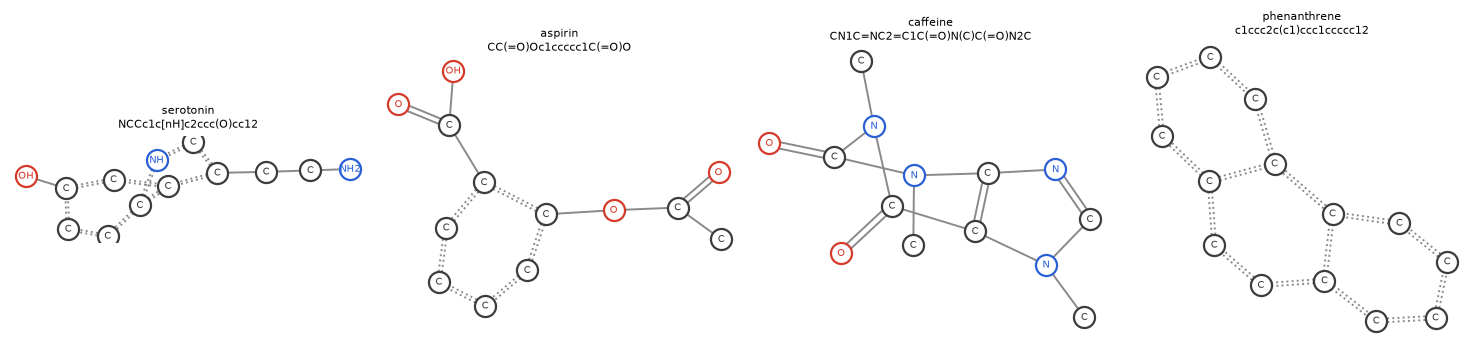

In [30]:
def layout_2d(n, bonds, steps=600, seed=0, bond_length=1.0):
    """Spring layout: bonds act as springs of length 1, all atom pairs repel."""
    rng = np.random.default_rng(seed)
    pos = rng.normal(scale=0.5, size=(n, 2))
    edges = np.array([(i, j) for i, j, _ in bonds]) if bonds else np.zeros((0, 2), int)
    for step in range(steps):
        delta = pos[:, None] - pos[None, :]
        dist = np.linalg.norm(delta, axis=-1) + 1e-9
        force = (delta / dist[..., None] / dist[..., None] ** 1.5).sum(1) * 0.08        # repulsion
        if len(edges):
            d = pos[edges[:, 1]] - pos[edges[:, 0]]
            length = np.linalg.norm(d, axis=1, keepdims=True) + 1e-9
            pull = d * (length - bond_length) / length * 0.35                           # springs
            np.add.at(force, edges[:, 0], pull)
            np.add.at(force, edges[:, 1], -pull)
        pos = pos + force * (1 - step / steps)
    return pos - pos.mean(0)

ATOM_COLOR = {'C': '#3c3c3c', 'N': '#2a5fd6', 'O': '#d63a2a', 'S': '#d4a017', 'F': '#1baf7a',
              'Cl': '#1baf7a', 'Br': '#8b4513', 'I': '#6250d6', 'P': '#e07b00'}

def draw_molecule(smiles, ax=None, title=None, seed=0):
    atoms, bonds = parse_smiles(smiles)
    pos = layout_2d(len(atoms), bonds, seed=seed)
    ax = ax or plt.gca()
    for i, j, o in bonds:
        p, q = pos[i], pos[j]
        normal = np.array([-(q - p)[1], (q - p)[0]])
        normal = normal / (np.linalg.norm(normal) + 1e-9) * 0.07
        zero = np.zeros(2)
        offsets = {1: [zero], 1.5: [0.6 * normal, -0.6 * normal], 2: [normal, -normal],
                   3: [2 * normal, zero, -2 * normal]}
        for off in offsets.get(o, [zero]):
            ax.plot([p[0] + off[0], q[0] + off[0]], [p[1] + off[1], q[1] + off[1]],
                    color='#8a8a8a', lw=1.4, zorder=1, ls=':' if o == 1.5 else '-')
    for k, a in enumerate(atoms):
        label = a['symbol'] + ('H' + (str(a['h']) if a['h'] > 1 else '') if a['h'] and a['symbol'] != 'C' else '')
        ax.scatter(*pos[k], s=230, color='white', edgecolors=ATOM_COLOR.get(a['symbol'], '#6250d6'), lw=1.6, zorder=2)
        ax.text(*pos[k], label, ha='center', va='center', fontsize=7.5, zorder=3,
                color=ATOM_COLOR.get(a['symbol'], '#6250d6'))
    ax.set_aspect('equal'); ax.axis('off')
    ax.set_title(title or f'{smiles}\n{formula(atoms)}', fontsize=8)

fig, axes = plt.subplots(1, 4, figsize=(15, 3.4))
for ax, (smi, name) in zip(axes, [(SEROTONIN, 'serotonin'), ('CC(=O)Oc1ccccc1C(=O)O', 'aspirin'),
                                  ('CN1C=NC2=C1C(=O)N(C)C(=O)N2C', 'caffeine'),
                                  ('c1ccc2c(c1)ccc1ccccc12', 'phenanthrene')]):
    draw_molecule(smi, ax, title=f'{name}\n{smi}')
plt.tight_layout(); plt.show()

## 7.4. The same molecule, many strings

One property of SMILES is worth seeing with our own eyes, because it is the reason datasets are deduplicated by graph and not by string: the same molecule has many valid SMILES, depending on which atom you start from and how you walk.

Below we write a few molecules in several ways and compare the graphs with a Weisfeiler-Leman hash — the same colour-refinement idea, used here as a canonical form. Two of the groups also contain the same ring system written in its Kekulé form (alternating single and double bonds) and in its aromatic form (lower-case atoms), which is where a naive comparison of molecular graphs gets into trouble.

In [31]:
def wl_hash(atoms, bonds, rounds=4):
    """Weisfeiler-Leman colour refinement as a canonical label of the molecular graph."""
    colors = [hash((ATOMIC_NUMBER.get(a['symbol'], 0), a['charge'], a['h'], a['aromatic'])) for a in atoms]
    adj = collections.defaultdict(list)
    for i, j, o in bonds:
        adj[i].append((j, o)); adj[j].append((i, o))
    for _ in range(rounds):
        colors = [hash((c, tuple(sorted((o, colors[n]) for n, o in adj[k])))) for k, c in enumerate(colors)]
    return hash(tuple(sorted(colors)))

groups = {'ethanol, 4 spellings': ['CCO', 'OCC', 'C(O)C', '[CH3][CH2][OH]'],
          'aspirin, 2 spellings': ['CC(=O)Oc1ccccc1C(=O)O', 'OC(=O)c1ccccc1OC(C)=O'],
          'benzene, Kekule vs aromatic': ['C1=CC=CC=C1', 'c1ccccc1'],
          'caffeine, Kekule vs aromatic': ['CN1C=NC2=C1C(=O)N(C)C(=O)N2C', 'Cn1cnc2c1c(=O)n(C)c(=O)n2C']}
for name, variants in groups.items():
    hashes = {wl_hash(*parse_smiles(s)) for s in variants}
    print(f'{name:<10} {len(variants)} spellings -> {len(hashes)} distinct graph(s): '
          f'{"same molecule" if len(hashes) == 1 else "DIFFERENT"}')
    for s in variants:
        a, b = parse_smiles(s)
        print(f'    {s:<34} {formula(a)}')

ethanol, 4 spellings 4 spellings -> 1 distinct graph(s): same molecule
    CCO                                C2H6O
    OCC                                C2H6O
    C(O)C                              C2H6O
    [CH3][CH2][OH]                     C2H6O
aspirin, 2 spellings 2 spellings -> 1 distinct graph(s): same molecule
    CC(=O)Oc1ccccc1C(=O)O              C9H8O4
    OC(=O)c1ccccc1OC(C)=O              C9H8O4
benzene, Kekule vs aromatic 2 spellings -> 2 distinct graph(s): DIFFERENT
    C1=CC=CC=C1                        C6H6
    c1ccccc1                           C6H6
caffeine, Kekule vs aromatic 2 spellings -> 2 distinct graph(s): DIFFERENT
    CN1C=NC2=C1C(=O)N(C)C(=O)N2C       C8H10N4O2
    Cn1cnc2c1c(=O)n(C)c(=O)n2C         C8H10N4O2


## 7.5. Atom and bond features, and a check against the dataset

What goes into the node and edge vectors: the element, the charge, the number of hydrogens, the degree, aromaticity, ring membership, and the bond type. 

The MoleculeNet datasets we are about to use ship exactly those features, computed by RDKit when the benchmark was built, so we can use them as ground truth for our parser: we parse the SMILES ourselves and compare, atom by atom, with the features in the file.

In [ ]:
def read_gz_csv(zf, name):
    return gzip.decompress(zf.open(name).read()).decode().strip().splitlines()

def load_moleculenet(name):
    """One MoleculeNet dataset in the OGB packaging: SMILES, graphs, labels and the scaffold split."""
    zf = zipfile.ZipFile(f'{DATA}/ogb_raw/{name}.zip')
    mol = read_gz_csv(zf, f'{name}/mapping/mol.csv.gz')
    header = mol[0].split(',')
    smiles = [line.split(',')[header.index('smiles')] for line in mol[1:]]
    get = lambda f, dt=np.int64: np.array([l.split(',') for l in read_gz_csv(zf, f'{name}/raw/{f}.csv.gz')], dtype=dt)
    y = np.array([[float(v) if v not in ('', 'nan') else np.nan for v in l.split(',')]
                  for l in read_gz_csv(zf, f'{name}/raw/graph-label.csv.gz')])
    return dict(name=name, smiles=smiles, x=get('node-feat'), edge=get('edge').T, edge_feat=get('edge-feat'),
                n_nodes=np.array(read_gz_csv(zf, f'{name}/raw/num-node-list.csv.gz'), dtype=np.int64),
                n_edges=np.array(read_gz_csv(zf, f'{name}/raw/num-edge-list.csv.gz'), dtype=np.int64), y=y,
                split={s: np.array(read_gz_csv(zf, f'{name}/split/scaffold/{s}.csv.gz'), dtype=np.int64)
                       for s in ('train', 'valid', 'test')})

def atom_features(atoms, bonds):
    """[atomic number, charge, #H, degree (with H), aromatic, in a ring]."""
    degree = [0] * len(atoms)
    for i, j, _ in bonds:
        degree[i] += 1; degree[j] += 1
    on_ring, _ = ring_membership(len(atoms), bonds)
    return np.array([[ATOMIC_NUMBER.get(a['symbol'], 0), a['charge'], a['h'], degree[k] + a['h'],
                      int(a['aromatic']), int(on_ring[k])] for k, a in enumerate(atoms)])

TOX21 = load_moleculenet('tox21')
offsets = np.r_[0, np.cumsum(TOX21['n_nodes'])]
exact = total = failed = 0
for g, smi in enumerate(TOX21['smiles']):
    try:
        atoms, bonds = parse_smiles(smi)
    except SmilesError:
        failed += 1; continue
    ours = atom_features(atoms, bonds)
    ref = TOX21['x'][offsets[g]:offsets[g + 1]]
    if len(ours) != len(ref):
        continue
    # the OGB columns: 0 atomic number - 1, 2 #H, 3 charge + 5, 4 ... , 7 aromatic, 8 in a ring
    reference = np.stack([ref[:, 0] + 1, ref[:, 3] - 5, ref[:, 4], ref[:, 2], ref[:, 7], ref[:, 8]], 1)
    exact += (ours == reference).all(1).sum(); total += len(ours)
print(f'Tox21: {len(TOX21["smiles"]):,} molecules, our parser failed on {failed}')
print(f'atoms whose 6 features match the reference exactly: {exact:,} / {total:,} = {exact / total:.4%}')

Tox21: 7,831 molecules, our parser failed on 0
atoms whose 6 features match the reference exactly: 145,451 / 145,459 = 99.9945%


# 8. Molecular property prediction

## 8.1. The task and the split

The problem: given graphs $G_i$ with targets $Y_i$, train $M$ with $Y_i = M(G_i)$ end-to-end, $Y$ a scalar for regression and a class for classification. 

We use two MoleculeNet datasets:

* Tox21 (toxicology): 7831 molecules, 12 binary tasks (one per biological assay) and missing labels everywhere — most molecules were only tested in some assays. The metric is ROC-AUC, averaged over the tasks.

* ESOL (a physical property): 1128 molecules, one regression target, the log-solubility in water. The metric is RMSE.

Both use the scaffold split that ships with the benchmark: molecules are grouped by their Bemis-Murcko skeleton, and whole scaffolds go to train, validation or test. 

A random split would put two analogues of the same series on both sides and measure almost nothing; a scaffold split asks the model to generalise to a chemical series it has never seen, which is what drug discovery actually needs.

In [33]:
ATOM_DIMS = [119, 4, 12, 12, 10, 6, 6, 2, 2]    # the 9 categorical atom features of the benchmark
BOND_DIMS = [5, 6, 2]                           # bond type, stereo, conjugated

class GraphSet:
    """All the graphs of a dataset in flat tensors; `batch(idx)` builds their disjoint union on the GPU."""
    def __init__(self, d):
        self.name, self.smiles, self.n = d['name'], d['smiles'], len(d['smiles'])
        self.x = torch.tensor(d['x'], device=device)
        self.e = torch.tensor(d['edge'], device=device)
        self.ef = torch.tensor(d['edge_feat'], device=device)
        nn_, ne = torch.tensor(d['n_nodes'], device=device), torch.tensor(d['n_edges'], device=device)
        self.nn, self.ne = nn_, ne
        self.node_ptr = torch.cat([nn_.new_zeros(1), nn_.cumsum(0)])
        self.edge_ptr = torch.cat([ne.new_zeros(1), ne.cumsum(0)])
        self.y = torch.tensor(d['y'], dtype=torch.float32, device=device)
        self.split = {k: torch.tensor(v, device=device) for k, v in d['split'].items()}
        self.n_tasks = self.y.size(1)

    def batch(self, idx):
        nn_, ne = self.nn[idx], self.ne[idx]
        g_node = torch.repeat_interleave(torch.arange(len(idx), device=device), nn_)
        start = torch.cumsum(nn_, 0) - nn_
        nodes = self.node_ptr[idx][g_node] + torch.arange(int(nn_.sum()), device=device) - start[g_node]
        g_edge = torch.repeat_interleave(torch.arange(len(idx), device=device), ne)
        e_start = torch.cumsum(ne, 0) - ne
        edges = self.edge_ptr[idx][g_edge] + torch.arange(int(ne.sum()), device=device) - e_start[g_edge]
        ei = self.e[:, edges] + start[g_edge]                      # ★ KEY: shift node ids into the union
        ei = torch.cat([ei, ei.flip(0)], 1)                        # ★ KEY: a bond is stored once, messages go both ways
        ef = torch.cat([self.ef[edges], self.ef[edges]])
        return self.x[nodes], ei, ef, g_node, len(idx)

TOX21_GS = GraphSet(TOX21)
ESOL_GS = GraphSet(load_moleculenet('esol'))
for gs in (TOX21_GS, ESOL_GS):
    sizes = gs.nn.float()
    print(f'{gs.name:<7} {gs.n:>5,} molecules | {gs.n_tasks:>2} task(s) | {sizes.mean():.1f} atoms on average '
          f'(max {int(sizes.max())}) | split {len(gs.split["train"]):,}/{len(gs.split["valid"]):,}/{len(gs.split["test"]):,}')
missing = torch.isnan(TOX21_GS.y).float().mean().item()
print(f'Tox21 labels that are missing: {missing:.1%}  -> the loss has to be masked')

tox21   7,831 molecules | 12 task(s) | 18.6 atoms on average (max 132) | split 6,264/783/784
esol    1,128 molecules |  1 task(s) | 13.3 atoms on average (max 55) | split 902/113/113
Tox21 labels that are missing: 17.1%  -> the loss has to be masked


## 8.2. Five architectures

All five follow the same recipe — embed the atom features, pass messages $L$ times, pool, predict — and differ only in how a message is formed:

| model | message from $j$ to $i$ |
|:--|:--|
| GCN | $\tilde a_{ij}\,\mathbf h_j$, degree-normalised, no edge information |
| GraphSAGE | mean of the neighbours, concatenated with the node itself |
| GIN | sum of the neighbours, $(1 + \epsilon)\mathbf h_i + \sum_j \mathbf h_j$, then an MLP |
| GIN-E | the same, with the bond embedding added to the message |
| GAT | $\alpha_{ij}\mathbf W\mathbf h_j$ with attention coefficients |
| Graph transformer | attention with queries and keys, as in `TransformerConv` |

GIN-E is the one that uses the bond features, which is why it is usually the strongest on molecules: a double bond and a single bond between the same two carbons are different chemistry.

In [ ]:
class FeatureEmbedding(nn.Module):
    """Sum of one embedding table per categorical feature."""
    def __init__(self, dims, dim):
        super().__init__()
        self.embs = nn.ModuleList([nn.Embedding(n, dim) for n in dims])
    def forward(self, x):
        return sum(emb(x[:, k]) for k, emb in enumerate(self.embs))

def scatter_mean(src, index, n):
    out = torch.zeros(n, src.size(1), device=src.device, dtype=src.dtype).index_add_(0, index, src)
    return out / torch.bincount(index, minlength=n).clamp(min=1)[:, None]

def scatter_softmax(src, index, n):
    top = torch.full((n,), -1e9, device=src.device).scatter_reduce(0, index, src, 'amax')
    ex = torch.exp(src - top[index])
    return ex / torch.zeros(n, device=src.device).index_add_(0, index, ex)[index].clamp(min=1e-16)

class MolGNN(nn.Module):
    """One backbone, six message functions."""
    def __init__(self, conv='gin-e', dim=128, layers=4, out=1, readout='mean', dropout=0.2, heads=4):
        super().__init__()
        self.conv, self.layers, self.readout, self.dropout = conv, layers, readout, dropout
        self.atom = FeatureEmbedding(ATOM_DIMS, dim)
        self.bond = nn.ModuleList([FeatureEmbedding(BOND_DIMS, dim) for _ in range(layers)]) if conv == 'gin-e' else None
        self.bns = nn.ModuleList([nn.BatchNorm1d(dim) for _ in range(layers)])
        if conv in ('gin', 'gin-e'):
            self.mlps = nn.ModuleList([nn.Sequential(nn.Linear(dim, 2 * dim), nn.BatchNorm1d(2 * dim), nn.ReLU(),
                                                     nn.Linear(2 * dim, dim)) for _ in range(layers)])
            self.eps = nn.Parameter(torch.zeros(layers))
        elif conv == 'gcn':
            self.lins = nn.ModuleList([nn.Linear(dim, dim) for _ in range(layers)])
        elif conv == 'sage':
            self.lins = nn.ModuleList([nn.Linear(2 * dim, dim) for _ in range(layers)])
        elif conv in ('gat', 'transformer'):
            self.heads, self.dh = heads, dim // heads
            self.lins = nn.ModuleList([nn.Linear(dim, dim) for _ in range(layers)])
            if conv == 'gat':
                self.att = nn.ParameterList([nn.Parameter(torch.randn(2 * dim) * 0.1) for _ in range(layers)])
            else:
                self.q = nn.ModuleList([nn.Linear(dim, dim) for _ in range(layers)])
                self.k = nn.ModuleList([nn.Linear(dim, dim) for _ in range(layers)])
        if readout == 'attention':
            self.gate = nn.Linear(dim, 1)
        self.head = nn.Sequential(nn.Linear(dim, dim), nn.ReLU(), nn.Dropout(dropout), nn.Linear(dim, out))

    def message_passing(self, x, ei, ef):
        h = self.atom(x)
        src, dst = ei[0], ei[1]
        n = h.size(0)
        deg = torch.bincount(dst, minlength=n).float().clamp(min=1)
        norm = deg[src].pow(-0.5) * deg[dst].pow(-0.5)
        for l in range(self.layers):
            if self.conv in ('gin', 'gin-e'):
                m = h[src] + (self.bond[l](ef) if self.bond is not None else 0)
                agg = torch.zeros_like(h).index_add_(0, dst, F.relu(m))
                out = self.mlps[l]((1 + self.eps[l]) * h + agg)
            elif self.conv == 'gcn':
                agg = torch.zeros_like(h).index_add_(0, dst, h[src] * norm[:, None])
                out = self.lins[l](agg + h / deg[:, None])
            elif self.conv == 'sage':
                out = self.lins[l](torch.cat([h, scatter_mean(h[src], dst, n)], 1))
            else:
                z = self.lins[l](h).view(n, self.heads, self.dh)
                if self.conv == 'gat':
                    a = self.att[l].view(2, self.heads, self.dh)
                    logit = F.leaky_relu((z[src] * a[0]).sum(-1) + (z[dst] * a[1]).sum(-1), 0.2)
                else:
                    q = self.q[l](h).view(n, self.heads, self.dh); k = self.k[l](h).view(n, self.heads, self.dh)
                    logit = (q[dst] * k[src]).sum(-1) / math.sqrt(self.dh)
                alpha = torch.stack([scatter_softmax(logit[:, k_], dst, n) for k_ in range(self.heads)], 1)
                agg = torch.zeros_like(z).index_add_(0, dst, alpha[..., None] * z[src])
                out = agg.reshape(n, -1) + h
            h2 = self.bns[l](out)
            h = F.dropout(F.relu(h2) if l < self.layers - 1 else h2, self.dropout, self.training)
        return h

    def pool(self, h, batch, B):
        if self.readout == 'sum':
            return torch.zeros(B, h.size(1), device=h.device).index_add_(0, batch, h)
        if self.readout == 'mean':
            return scatter_mean(h, batch, B)
        if self.readout == 'max':
            return torch.full((B, h.size(1)), -1e9, device=h.device).scatter_reduce(0, batch[:, None].expand_as(h), h, 'amax')
        if self.readout == 'attention':                      # ★ KEY: attention pooling
            a = scatter_softmax(self.gate(h).squeeze(1), batch, B)
            return torch.zeros(B, h.size(1), device=h.device).index_add_(0, batch, a[:, None] * h)

    def forward(self, x, ei, ef, batch, B):
        return self.head(self.pool(self.message_passing(x, ei, ef), batch, B))

In [35]:
def roc_auc(y, score):
    """Mean ROC-AUC over the tasks, ignoring the missing labels (rank statistic, no sklearn needed)."""
    aucs = []
    for t in range(y.shape[1]):
        m = ~np.isnan(y[:, t])
        yt, st = y[m, t], score[m, t]
        n_pos, n_neg = (yt == 1).sum(), (yt == 0).sum()
        if n_pos == 0 or n_neg == 0:
            continue
        order = np.argsort(st)
        rank = np.empty(len(st)); rank[order] = np.arange(1, len(st) + 1)
        # average the ranks of ties
        _, inv, counts = np.unique(st, return_inverse=True, return_counts=True)
        mean_rank = np.zeros(len(counts)); np.add.at(mean_rank, inv, rank); mean_rank /= counts
        rank = mean_rank[inv]
        aucs.append((rank[yt == 1].sum() - n_pos * (n_pos + 1) / 2) / (n_pos * n_neg))
    return float(np.mean(aucs))

def train_molgnn(gs, make_model, task='cls', epochs=40, lr=1e-3, batch_size=128, seed=0, verbose=False):
    """Train, select the epoch on the validation set, report the test score of that epoch."""
    set_seed(seed)
    model = make_model().to(device)
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    tr, va, te = gs.split['train'], gs.split['valid'], gs.split['test']
    mu, sd = gs.y[tr].mean(0), gs.y[tr].std(0)
    t0 = time.time()

    @torch.no_grad()
    def predict(idx):
        model.eval()
        return torch.cat([model(*gs.batch(idx[k:k + 512])) for k in range(0, len(idx), 512)])

    def score(idx):
        p = predict(idx)
        if task == 'cls':
            return roc_auc(gs.y[idx].cpu().numpy(), p.cpu().numpy())
        return -((p * sd + mu - gs.y[idx]) ** 2).mean().sqrt().item()        # negative RMSE: higher is better

    best = (-1e9, -1e9, 0)
    for epoch in range(1, epochs + 1):
        model.train()
        perm = tr[torch.randperm(len(tr), device=device)]
        for k in range(0, len(perm), batch_size):
            idx = perm[k:k + batch_size]
            if len(idx) < 2:
                continue
            out = model(*gs.batch(idx)); y = gs.y[idx]
            if task == 'cls':
                m = ~torch.isnan(y)
                loss = F.binary_cross_entropy_with_logits(out[m], y[m])      # ★ KEY: the missing labels are masked out
            else:
                loss = F.mse_loss(out, (y - mu) / sd)
            opt.zero_grad(); loss.backward(); opt.step()
        v = score(va)
        if v > best[0]:
            best = (v, score(te), epoch)
        if verbose and epoch % 10 == 0:
            print(f'  epoch {epoch:>3} | validation {abs(v):.4f}')
    return dict(val=abs(best[0]), test=abs(best[1]), epoch=best[2], time=time.time() - t0, params=n_params(model))

MOL_RESULTS = {}
print(f"{'model':<22}{'Tox21 ROC-AUC':>15}{'ESOL RMSE':>12}{'params':>10}{'time':>8}")
for conv, label in [('gcn', 'GCN'), ('sage', 'GraphSAGE'), ('gin', 'GIN'), ('gin-e', 'GIN + bonds'),
                    ('gat', 'GAT'), ('transformer', 'Graph transformer')]:
    a = train_molgnn(TOX21_GS, lambda: MolGNN(conv, out=TOX21_GS.n_tasks), 'cls')
    b = train_molgnn(ESOL_GS, lambda: MolGNN(conv, out=1), 'reg')
    MOL_RESULTS[label] = dict(tox21=a['test'], esol=b['test'], params=a['params'], time=a['time'] + b['time'])
    print(f"{label:<22}{a['test']:>15.4f}{b['test']:>12.4f}{a['params']:>10,}{a['time'] + b['time']:>7.0f}s")

model                   Tox21 ROC-AUC   ESOL RMSE    params    time
GCN                            0.7466      1.1041   107,276     41s
GraphSAGE                      0.7371      1.3531   172,812     47s
GIN                            0.7671      1.2881   306,960     51s
GIN + bonds                    0.7508      1.2200   313,616     68s
GAT                            0.7420      1.2401   108,300    142s
Graph transformer              0.7509      1.3269   239,372    146s


## 8.3. The readout 

The pooling functions: mean, max, sum, attention. 

The choice is not cosmetic — it decides what the graph vector means. 

A sum is extensive: it grows with the molecule, which is right for a property like solubility that scales with size. 

A mean is intensive and invariant to size. 

Attention learns which atoms matter, which is the closest thing to the functional group decides.

In [36]:
print(f"{'readout':<14}{'Tox21 ROC-AUC':>15}{'ESOL RMSE':>12}")
READOUTS = {}
for ro in ['mean', 'sum', 'max', 'attention']:
    a = train_molgnn(TOX21_GS, lambda: MolGNN('gin-e', out=TOX21_GS.n_tasks, readout=ro), 'cls')
    b = train_molgnn(ESOL_GS, lambda: MolGNN('gin-e', out=1, readout=ro), 'reg')
    READOUTS[ro] = (a['test'], b['test'])
    print(f'{ro:<14}{a["test"]:>15.4f}{b["test"]:>12.4f}')

readout         Tox21 ROC-AUC   ESOL RMSE
mean                   0.7449      1.2001
sum                    0.7222      1.1463
max                    0.7352      1.2035
attention              0.7339      1.2815


# 9. Equivariant GNNs: using the 3-D structure

## 9.1. Why coordinates, and the three equivariances

Everything so far used the bond graph only. 

Why that is not enough: properties depend on bond lengths, angles and dihedrals, that is, on where the atoms actually are. 

But the moment we feed coordinates to a network we create a problem — the coordinates of a molecule are not unique. 

Translate it, rotate it, or renumber the atoms, and it is the same molecule.

Name the three symmetries a model must respect:

* translation: $\phi(\mathbf x + g) = \phi(\mathbf x) + g$ for an output that is a position, and $\phi(\mathbf x + g) = \phi(\mathbf x)$ for a scalar;
* rotation / reflection: $\phi(Q\mathbf x) = Q\phi(\mathbf x)$, or $=\phi(\mathbf x)$ for a scalar;
* permutation: $\phi(P\mathbf x) = P\phi(\mathbf x)$.

We use QM9 (134k small molecules with their equilibrium geometries computed by DFT) and predict the dipole moment $\mu$, a property that is impossible to read off the bond graph alone: it depends on how the polar groups are arranged in space.

In [37]:
QM9_NPZ = f'{DATA}/qm9_flat.npz'
ZMAP = {1: 0, 6: 1, 7: 2, 8: 3, 9: 4}                   # H C N O F -> 0..4, +1 because 0 means padding
QM9_TARGET = {'mu (dipole, D)': 0, 'alpha (polarisability)': 1, 'homo': 2, 'lumo': 3, 'gap (eV)': 4, 'Cv': 11}

def load_qm9(n_mols=15000, seed=0, max_atoms=29):
    """A random subset of QM9 as dense padded tensors [n, N] / [n, N, 3] / [n, N, N]."""
    f = np.load(QM9_NPZ)
    node_ptr, edge_ptr = f['node_ptr'], f['edge_ptr']
    idx = np.random.default_rng(seed).permutation(len(node_ptr) - 1)[:n_mols]
    Z = np.zeros((len(idx), max_atoms), dtype=np.int64)
    POS = np.zeros((len(idx), max_atoms, 3), dtype=np.float32)
    BOND = np.zeros((len(idx), max_atoms, max_atoms), dtype=np.int8)
    z, pos, e, ea = f['z'], f['pos'], f['edge'], f['edge_attr']
    for k, g in enumerate(idx):
        a, b = node_ptr[g], node_ptr[g + 1]
        Z[k, :b - a] = [ZMAP[int(v)] + 1 for v in z[a:b]]
        POS[k, :b - a] = pos[a:b]
        s, t = edge_ptr[g], edge_ptr[g + 1]
        BOND[k, e[0, s:t], e[1, s:t]] = ea[s:t] + 1
    return dict(Z=Z, POS=POS, BOND=BOND, y=f['y'][idx])

class Molecules3D:
    def __init__(self, raw, target='mu (dipole, D)', splits=(0.8, 0.1)):
        n = len(raw['Z'])
        self.Z = torch.tensor(raw['Z'], device=device)
        self.mask = self.Z > 0
        pos = torch.tensor(raw['POS'], device=device)
        self.pos = pos - (pos * self.mask[..., None]).sum(1, keepdim=True) / self.mask.sum(1)[:, None, None]
        self.bond = torch.tensor(raw['BOND'], device=device)            # int8: only GIN3D reads it
        self.y = torch.tensor(raw['y'][:, QM9_TARGET[target]], device=device)
        a, b = int(splits[0] * n), int(sum(splits) * n)
        self.tr = torch.arange(a, device=device)
        self.va = torch.arange(a, b, device=device)
        self.te = torch.arange(b, n, device=device)
        self.mu, self.sd = self.y[self.tr].mean(), self.y[self.tr].std()
        self.target = target

QM9 = Molecules3D(load_qm9(15000))
print(f'{len(QM9.Z):,} molecules | {QM9.mask.sum(1).float().mean():.1f} atoms on average (with hydrogens) | '
      f'target: {QM9.target}, mean {QM9.mu:.3f}, std {QM9.sd:.3f}')
print(f'predicting the training mean for everything would give MAE {(QM9.y[QM9.te] - QM9.mu).abs().mean():.4f}')

15,000 molecules | 18.1 atoms on average (with hydrogens) | target: mu (dipole, D), mean 2.665, std 1.494
predicting the training mean for everything would give MAE 1.1220


## 9.2. Checking the symmetries numerically

Before building anything, let make the three equivariances concrete on one molecule: translate it, rotate it with a random orthogonal $Q$, and permute its atoms, and watch what is preserved. 

The pairwise distances survive all three, which is precisely why every model below is built on distances rather than on raw coordinates.

In [38]:
set_seed(0)
k = 0
n_at = int(QM9.mask[k].sum())
x = QM9.pos[k, :n_at]
Q, _ = torch.linalg.qr(torch.randn(3, 3, device=device))                 # a random rotation / reflection
g = torch.tensor([1.0, -2.0, 0.5], device=device)
perm = torch.randperm(n_at, device=device)

def pairwise(x):
    return torch.cdist(x, x)

print(f'a molecule with {n_at} atoms')
print(f'  max |x| before                        {x.abs().max():.4f}')
for name, y in [('translated  x + g', x + g), ('rotated     Qx', x @ Q.T), ('permuted    Px', x[perm])]:
    d0, d1 = pairwise(x), pairwise(y)
    if 'permuted' in name:
        d1 = pairwise(y)[torch.argsort(perm)][:, torch.argsort(perm)]
    print(f'  {name:<22} max change of a coordinate {(y - x).abs().max():8.4f} | '
          f'max change of a pairwise distance {(d1 - d0).abs().max():.2e}')
print('\nThe distances are invariant to all three. A scalar property must be invariant too.')
print('A predicted position must rotate and translate with the molecule.')

a molecule with 13 atoms
  max |x| before                        3.0014
  translated  x + g      max change of a coordinate   2.0000 | max change of a pairwise distance 4.77e-07
  rotated     Qx         max change of a coordinate   5.8941 | max change of a pairwise distance 9.54e-07
  permuted    Px         max change of a coordinate   3.6977 | max change of a pairwise distance 0.00e+00

The distances are invariant to all three. A scalar property must be invariant too.
A predicted position must rotate and translate with the molecule.


## 9.3. Three models: bonds only, distances, and the EGCL

* GIN on the bonds — the Part-II baseline, blind to geometry.

* Invariant MPNN — the same message passing but on the complete graph, with $\|\mathbf x_i - \mathbf x_j\|^2$ as the only geometric input. Invariant by construction, because it never sees a coordinate, only a distance.

* EGNN / EGCL — the same, plus a coordinate update, which makes the layer equivariant rather than merely invariant, and a variant that also feeds the bond type $a_{ij}$ into the message, so that the model sees the chemistry and the geometry at once:

$$\mathbf m_{ij} = \phi_e\big(\mathbf h_i, \mathbf h_j, \|\mathbf x_i - \mathbf x_j\|^2, a_{ij}\big),\qquad
\mathbf x_i^{l+1} = \mathbf x_i^{l} + C\sum_{j \ne i}(\mathbf x_i^l - \mathbf x_j^l)\,\phi_x(\mathbf m_{ij}),$$
$$\mathbf m_i = \sum_{j\neq i}\mathbf m_{ij},\qquad \mathbf h_i^{l+1} = \phi_h(\mathbf h_i^l, \mathbf m_i).$$

The coordinate update is a weighted sum of the relative vectors $\mathbf x_i - \mathbf x_j$, so rotating the input rotates the update exactly as much, and the layer stays equivariant whatever $\phi_x$ does.

In [42]:
class GIN3D(nn.Module):
    """Bonds only, no coordinates: the baseline on QM9."""
    def __init__(self, dim=128, layers=4):
        super().__init__()
        self.emb = nn.Embedding(6, dim)
        self.bond = nn.Embedding(5, dim)
        self.mlps = nn.ModuleList([nn.Sequential(nn.Linear(dim, 2 * dim), nn.SiLU(), nn.Linear(2 * dim, dim))
                                   for _ in range(layers)])
        self.head = nn.Sequential(nn.Linear(dim, dim), nn.SiLU(), nn.Linear(dim, 1))
    def forward(self, z, pos, bond, mask):
        h = self.emb(z)
        A = (bond > 0).float()
        for mlp in self.mlps:
            h = h + mlp(h + A @ h + torch.einsum('bij,bijd->bid', A, self.bond(bond.long())))
            h = h * mask[..., None]
        return self.head((h * mask[..., None]).sum(1))

class EGNN(nn.Module):
    """The EGCL, coord_update=False leaves an SE(3)-invariant message-passing network."""
    def __init__(self, dim=128, layers=4, coord_update=True, use_bonds=False):
        super().__init__()
        self.emb = nn.Embedding(6, dim)
        extra = 5 if use_bonds else 0
        self.phi_e = nn.ModuleList([nn.Sequential(nn.Linear(2 * dim + 1 + extra, dim), nn.SiLU(),
                                                  nn.Linear(dim, dim), nn.SiLU()) for _ in range(layers)])
        self.phi_h = nn.ModuleList([nn.Sequential(nn.Linear(2 * dim, dim), nn.SiLU(), nn.Linear(dim, dim))
                                    for _ in range(layers)])
        self.phi_inf = nn.ModuleList([nn.Sequential(nn.Linear(dim, 1), nn.Sigmoid()) for _ in range(layers)])
        self.phi_x = nn.ModuleList([nn.Sequential(nn.Linear(dim, dim), nn.SiLU(), nn.Linear(dim, 1))
                                    for _ in range(layers)]) if coord_update else None
        self.head = nn.Sequential(nn.Linear(dim, dim), nn.SiLU(), nn.Linear(dim, 1))
        self.use_bonds = use_bonds

    def forward(self, z, pos, bond, mask, return_positions=False):
        h, x = self.emb(z), pos
        pair = (mask[:, :, None] & mask[:, None, :]) & ~torch.eye(z.size(1), dtype=torch.bool, device=z.device)
        pair = pair.float()[..., None]
        bond_1hot = F.one_hot(bond.long(), 5).float() if self.use_bonds else None
        for l in range(len(self.phi_e)):
            diff = x[:, :, None] - x[:, None, :]                              # x_i - x_j
            d2 = (diff ** 2).sum(-1, keepdim=True)                            # ★ KEY: only the squared distance enters
            inp = [h[:, :, None].expand(-1, -1, z.size(1), -1), h[:, None].expand(-1, z.size(1), -1, -1), d2]
            if self.use_bonds:
                inp.append(bond_1hot)
            m_ij = self.phi_e[l](torch.cat(inp, -1)) * pair
            if self.phi_x is not None:                                        # ★ KEY: equivariant coordinate update
                # ★ KEY: phi_x(0) is not 0, so the padded pairs have to be masked HERE, after phi_x,
                #        otherwise a padded atom at the origin pulls on x_i and breaks the equivariance
                weight = self.phi_x[l](m_ij) * pair
                x = x + (diff * weight).sum(2) / pair.sum(2).clamp(min=1) * mask[..., None]
            m_i = (m_ij * self.phi_inf[l](m_ij)).sum(2)                       # attention-weighted sum
            h = (h + self.phi_h[l](torch.cat([h, m_i], -1))) * mask[..., None]
        if return_positions:
            return x
        return self.head((h * mask[..., None]).sum(1))

def train_3d(model, data, epochs=40, lr=1e-3, batch_size=128, seed=0, augment=False, verbose=False):
    set_seed(seed)
    model = model.to(device)
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, epochs)
    t0 = time.time()

    @torch.no_grad()
    def mae(idx):
        model.eval()
        out = [model(data.Z[i], data.pos[i], data.bond[i], data.mask[i]).squeeze(-1)
               for i in [idx[k:k + 256] for k in range(0, len(idx), 256)]]
        return ((torch.cat(out) * data.sd + data.mu) - data.y[idx]).abs().mean().item()

    best = (1e9, 1e9, 0)
    for epoch in range(1, epochs + 1):
        model.train()
        perm = data.tr[torch.randperm(len(data.tr), device=device)]
        for k in range(0, len(perm), batch_size):
            i = perm[k:k + batch_size]
            pos = data.pos[i]
            if augment:                                                        # random rotation of the input
                Q, _ = torch.linalg.qr(torch.randn(len(i), 3, 3, device=device))
                pos = pos @ Q
            out = model(data.Z[i], pos, data.bond[i], data.mask[i]).squeeze(-1)
            loss = F.l1_loss(out, (data.y[i] - data.mu) / data.sd)
            opt.zero_grad(); loss.backward(); opt.step()
        sched.step()
        v = mae(data.va)
        if v < best[0]:
            best = (v, mae(data.te), epoch)
        if verbose and epoch % 10 == 0:
            print(f'  epoch {epoch:>3} | validation MAE {v:.4f}')
    return dict(val=best[0], test=best[1], epoch=best[2], time=time.time() - t0,
                params=n_params(model), model=model)

QM9_RESULTS = {}
for label, make in [('GIN (bonds only)', lambda: GIN3D()),
                    ('invariant MPNN (distances)', lambda: EGNN(coord_update=False)),
                    ('EGNN', lambda: EGNN(coord_update=True)),
                    ('EGNN + bond features', lambda: EGNN(coord_update=True, use_bonds=True))]:
    QM9_RESULTS[label] = train_3d(make(), QM9)
    r = QM9_RESULTS[label]
    print(f'{label:<28} test MAE {r["test"]:.4f} D | {r["params"]:>8,} parameters | {r["time"]:>5.0f}s')

GIN (bonds only)             test MAE 0.6045 D |  281,729 parameters |    57s
invariant MPNN (distances)   test MAE 0.3374 D |  413,701 parameters |    72s
EGNN                         test MAE 0.2426 D |  480,265 parameters |   100s
EGNN + bond features         test MAE 0.2710 D |  482,825 parameters |   101s


## 9.4. Is the model really equivariant?

A claim of equivariance is a claim about the code, and it is cheap to test. 

We take the trained EGNN and check two things on the same molecules:

* the prediction must not move when we rotate and translate the input (invariance of a scalar);

* the updated coordinates must move exactly as the input did: $\mathbf x'(Q\mathbf x + g) = Q\,\mathbf x'(\mathbf x) + g$.

For comparison we do the same with a network that eats raw coordinates instead of distances.

In [43]:
class NaiveCoordinateNet(nn.Module):
    """What not to do: feed the raw (x, y, z) as node features."""
    def __init__(self, dim=128, layers=4):
        super().__init__()
        self.emb = nn.Embedding(6, dim)
        self.inp = nn.Linear(3, dim)
        self.mlps = nn.ModuleList([nn.Sequential(nn.Linear(dim, dim), nn.SiLU(), nn.Linear(dim, dim)) for _ in range(layers)])
        self.head = nn.Sequential(nn.Linear(dim, dim), nn.SiLU(), nn.Linear(dim, 1))
    def forward(self, z, pos, bond, mask):
        h = self.emb(z) + self.inp(pos)
        A = (bond > 0).float()
        for mlp in self.mlps:
            h = (h + mlp(A @ h + h)) * mask[..., None]
        return self.head((h * mask[..., None]).sum(1))

egnn = QM9_RESULTS['EGNN']['model']              
naive = NaiveCoordinateNet().to(device)

idx = QM9.te[:64]
z, pos, bond, mask = QM9.Z[idx], QM9.pos[idx], QM9.bond[idx], QM9.mask[idx]
Q, _ = torch.linalg.qr(torch.randn(3, 3, device=device))
g = torch.tensor([0.7, -1.3, 2.0], device=device)
moved = (pos @ Q.T + g) * mask[..., None]

with torch.no_grad():
    for name, model in [('EGNN (distances)', egnn), ('naive net (raw coordinates)', naive)]:
        a, b = model(z, pos, bond, mask), model(z, moved, bond, mask)
        print(f'{name:<30} |prediction change| after a rotation + translation: {(a - b).abs().max():.3e}')
    x1 = egnn(z, pos, bond, mask, return_positions=True)
    x2 = egnn(z, moved, bond, mask, return_positions=True)
    expected = (x1 @ Q.T + g) * mask[..., None]
    print(f'{"EGNN coordinate output":<30} |x\'(Qx + g) - (Qx\'(x) + g)|: '
          f'{((x2 - expected) * mask[..., None]).abs().max():.3e}   <- equivariant, not invariant')

EGNN (distances)               |prediction change| after a rotation + translation: 1.669e-06
naive net (raw coordinates)    |prediction change| after a rotation + translation: 2.622e+01
EGNN coordinate output         |x'(Qx + g) - (Qx'(x) + g)|: 7.510e-06   <- equivariant, not invariant


# 10. Learning without labels

The motivation: labelled molecules are the output of wet-lab experiments, so there are thousands of them, while unlabelled molecules are free and there are hundreds of millions. 

Training a GNN on a few thousand labels overfits and does not transfer. 

Group the answers into node-level, contrastive and subgraph-level strategies, we implement one of each and measure whether it helps.

Our setup: pre-train on the 41k unlabelled molecules of the HIV dataset (throw its labels away), then fine-tune on BACE (1513 molecules) and BBBP (2039) with the scaffold split.

In [44]:
UNLABELLED = GraphSet(load_moleculenet('hiv'))
BACE_GS = GraphSet(load_moleculenet('bace'))
BBBP_GS = GraphSet(load_moleculenet('bbbp'))
set_seed(0)
PRETRAIN_IDX = torch.randperm(UNLABELLED.n, device=device)[:20000]
print(f'pre-training pool: {len(PRETRAIN_IDX):,} molecules, {int(UNLABELLED.nn[PRETRAIN_IDX].sum()):,} atoms')
print(f'fine-tuning: BACE {BACE_GS.n:,} molecules, BBBP {BBBP_GS.n:,} molecules (scaffold split)')

pre-training pool: 20,000 molecules, 511,728 atoms
fine-tuning: BACE 1,513 molecules, BBBP 2,039 molecules (scaffold split)


## 10.1. Attribute masking

The node-level strategy: hide the attributes of 15% of the atoms and make the GNN predict them from their neighbourhood. 

To predict that a masked atom is an oxygen, the network has to learn what oxygens are usually bonded to — which is chemistry, learned without a single label.

In [45]:
class Pretrainer(nn.Module):
    """The GIN-E backbone of Section 8 with the three self-supervised heads."""
    def __init__(self, dim=128, layers=4, n_motifs=0):
        super().__init__()
        self.gnn = MolGNN('gin-e', dim=dim, layers=layers, out=1)
        self.atom_head = nn.Linear(dim, ATOM_DIMS[0])              # masked atom -> element
        self.project = nn.Sequential(nn.Linear(dim, dim), nn.ReLU(), nn.Linear(dim, dim))   # contrastive head
        self.motif_head = nn.Linear(dim, n_motifs) if n_motifs else None

def mask_atoms(x, rate=0.15):
    x = x.clone()
    which = torch.rand(len(x), device=device) < rate
    target = x[which, 0].clone()
    x[which, 0] = ATOM_DIMS[0] - 1                                 # ★ KEY: a reserved "masked" element id
    return x, which, target

def pretrain_masking(model, gs, idx, epochs=3, lr=1e-3, batch_size=256):
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    t0 = time.time()
    for epoch in range(1, epochs + 1):
        model.train(); losses, accs = [], []
        perm = idx[torch.randperm(len(idx), device=device)]
        for k in range(0, len(perm), batch_size):
            x, ei, ef, batch, B = gs.batch(perm[k:k + batch_size])
            x, which, target = mask_atoms(x)
            h = model.gnn.message_passing(x, ei, ef)
            logits = model.atom_head(h[which])
            loss = F.cross_entropy(logits, target)
            opt.zero_grad(); loss.backward(); opt.step()
            losses.append(loss.item()); accs.append((logits.argmax(1) == target).float().mean().item())
        print(f'  epoch {epoch}: loss {np.mean(losses):.4f} | masked-atom accuracy {np.mean(accs):.3f}')
    return time.time() - t0

set_seed(0)
masking_model = Pretrainer().to(device)
print('attribute masking:')
pretrain_masking(masking_model, UNLABELLED, PRETRAIN_IDX)

attribute masking:
  epoch 1: loss 0.5360 | masked-atom accuracy 0.892
  epoch 2: loss 0.1221 | masked-atom accuracy 0.964
  epoch 3: loss 0.0989 | masked-atom accuracy 0.970


9.964192390441895

## 10.2. Contrastive learning with graph augmentations

The contrastive strategy: build two augmented views of the same molecule, and train so that the two views of one molecule agree and views of different molecules do not,

$$\ell_n = -\log\frac{\exp(\text{sim}(\mathbf z_{n,i}, \mathbf z_{n,j})/\tau)}{\sum_{n'\neq n}\exp(\text{sim}(\mathbf z_{n,i}, \mathbf z_{n',j})/\tau)} .$$

The table lists the four augmentations and the prior each one assumes. We implement node dropping, edge perturbation and attribute masking, for molecules these augmentations are **not** semantics-preserving — deleting one atom of a functional group can turn a drug into something else.

In [46]:
def augment_graph(x, ei, ef, batch, B, kind='node_drop', rate=0.2):
    if kind == 'node_drop':
        keep = torch.rand(len(x), device=device) >= rate
        keep[torch.zeros(B, dtype=torch.long, device=device)] = True
        remap = torch.cumsum(keep.long(), 0) - 1
        e_keep = keep[ei[0]] & keep[ei[1]]
        return x[keep], remap[ei[:, e_keep]], ef[e_keep], batch[keep], B
    if kind == 'edge_perturb':
        keep = torch.rand(ei.size(1), device=device) >= rate
        return x, ei[:, keep], ef[keep], batch, B
    if kind == 'attr_mask':
        x = x.clone()
        x[torch.rand(len(x), device=device) < rate, 0] = ATOM_DIMS[0] - 1
        return x, ei, ef, batch, B
    if kind == 'subgraph':                                   # a coarse version: drop half of the atoms
        return augment_graph(x, ei, ef, batch, B, 'node_drop', 0.5)

def nt_xent(z1, z2, tau=0.1):
    z1, z2 = F.normalize(z1, dim=1), F.normalize(z2, dim=1)
    logits = z1 @ z2.T / tau
    labels = torch.arange(len(z1), device=device)
    return 0.5 * (F.cross_entropy(logits, labels) + F.cross_entropy(logits.T, labels))

def pretrain_contrastive(model, gs, idx, epochs=3, lr=1e-3, batch_size=256, kinds=('node_drop', 'attr_mask')):
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    for epoch in range(1, epochs + 1):
        model.train(); losses, accs = [], []
        perm = idx[torch.randperm(len(idx), device=device)]
        for k in range(0, len(perm), batch_size):
            b = gs.batch(perm[k:k + batch_size])
            if b[4] < 8:
                continue
            views = []
            for kind in kinds:
                x, ei, ef, batch, B = augment_graph(*b, kind=kind)
                h = model.gnn.message_passing(x, ei, ef)
                views.append(model.project(model.gnn.pool(h, batch, B)))
            loss = nt_xent(*views)
            opt.zero_grad(); loss.backward(); opt.step()
            losses.append(loss.item())
            with torch.no_grad():
                sim = F.normalize(views[0], dim=1) @ F.normalize(views[1], dim=1).T
                accs.append((sim.argmax(1) == torch.arange(len(sim), device=device)).float().mean().item())
        print(f'  epoch {epoch}: loss {np.mean(losses):.4f} | the matching view is the closest one '
              f'{np.mean(accs):.3f} of the time')

set_seed(0)
contrastive_model = Pretrainer().to(device)
print('contrastive learning:')
pretrain_contrastive(contrastive_model, UNLABELLED, PRETRAIN_IDX)

contrastive learning:
  epoch 1: loss 1.3508 | the matching view is the closest one 0.737 of the time
  epoch 2: loss 0.6219 | the matching view is the closest one 0.911 of the time
  epoch 3: loss 0.4821 | the matching view is the closest one 0.943 of the time


## 10.3. Motifs: a fragment vocabulary

Why node-level and contrastive objectives are not enough: chemistry happens at the level of functional groups, and a model that only ever predicts single atoms is not pushed to represent them. 

The subgraph-level strategies fix this by building a vocabulary of fragments mined by frequency, and asking the network which fragments a molecule contains (GROVER's motif prediction).

We mine the vocabulary with our own parser: break every single, acyclic bond — this keeps rings and double-bonded groups intact — and count the fragments that come out. 

In [47]:
def fragment(atoms, bonds):
    """Break every acyclic single bond and return the connected pieces."""
    _, on_ring_bond = ring_membership(len(atoms), bonds)
    keep = [e for e, (i, j, o) in enumerate(bonds) if on_ring_bond[e] or o != 1]
    parent = list(range(len(atoms)))
    def find(a):
        while parent[a] != a:
            parent[a] = parent[parent[a]]; a = parent[a]
        return a
    for e in keep:
        i, j, _ = bonds[e]
        parent[find(i)] = find(j)
    pieces = collections.defaultdict(list)
    for k in range(len(atoms)):
        pieces[find(k)].append(k)
    out = []
    for members in pieces.values():
        local = {a: k for k, a in enumerate(members)}
        sub_atoms = [atoms[a] for a in members]
        sub_bonds = [(local[bonds[e][0]], local[bonds[e][1]], bonds[e][2]) for e in keep
                     if bonds[e][0] in local and bonds[e][1] in local]
        out.append((wl_hash(sub_atoms, sub_bonds), formula(sub_atoms), len(members)))
    return out

counts, example = collections.Counter(), {}
parsed = 0
for smi in UNLABELLED.smiles[:8000]:
    try:
        atoms, bonds = parse_smiles(smi)
    except SmilesError:
        continue
    parsed += 1
    seen = set()
    for h, form, size in fragment(atoms, bonds):
        if size >= 2 and h not in seen:
            seen.add(h); counts[h] += 1
            example.setdefault(h, (form, size))

MOTIFS = [h for h, _ in counts.most_common(100)]
MOTIF_OF = {h: k for k, h in enumerate(MOTIFS)}
print(f'mined {len(counts):,} distinct fragments from {parsed:,} molecules; the 12 most frequent:')
for h, c in counts.most_common(12):
    form, size = example[h]
    print(f'  {form:<10} {size:>2} atoms   in {c / parsed:>6.1%} of the molecules')

mined 3,587 distinct fragments from 7,998 molecules; the 12 most frequent:
  CO          2 atoms   in  32.3% of the molecules
  C6H5        6 atoms   in  19.8% of the molecules
  C6H4        6 atoms   in  15.8% of the molecules
  O2S         3 atoms   in  10.5% of the molecules
  C6H3        6 atoms   in   6.7% of the molecules
  NO+         2 atoms   in   5.1% of the molecules
  CN          2 atoms   in   4.2% of the molecules
  CHN         2 atoms   in   3.4% of the molecules
  C6H4        6 atoms   in   3.4% of the molecules
  C2H2        2 atoms   in   3.0% of the molecules
  N2          2 atoms   in   2.6% of the molecules
  CHN         2 atoms   in   2.4% of the molecules


In [48]:
def motif_labels(gs, idx, n_motifs=len(MOTIFS)):
    y = torch.zeros(len(idx), n_motifs, device=device)
    for row, g in enumerate(idx.tolist()):
        try:
            atoms, bonds = parse_smiles(gs.smiles[g])
        except SmilesError:
            continue
        for h, _, size in fragment(atoms, bonds):
            if size >= 2 and h in MOTIF_OF:
                y[row, MOTIF_OF[h]] = 1
    return y

MOTIF_POOL = PRETRAIN_IDX[:8000]
MOTIF_Y = motif_labels(UNLABELLED, MOTIF_POOL)
print(f'motif labels: {MOTIF_Y.mean().item():.3%} of the (molecule, motif) pairs are positive, '
      f'{MOTIF_Y.sum(1).mean():.1f} motifs per molecule')

def pretrain_motifs(model, gs, idx, y, epochs=4, lr=1e-3, batch_size=256):
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    for epoch in range(1, epochs + 1):
        model.train(); losses, f1s = [], []
        perm = torch.randperm(len(idx), device=device)
        for k in range(0, len(perm), batch_size):
            sel = perm[k:k + batch_size]
            x, ei, ef, batch, B = gs.batch(idx[sel])
            h = model.gnn.pool(model.gnn.message_passing(x, ei, ef), batch, B)
            logits = model.motif_head(h)
            loss = F.binary_cross_entropy_with_logits(logits, y[sel])
            opt.zero_grad(); loss.backward(); opt.step()
            losses.append(loss.item())
            pred = logits > 0
            tp = (pred & (y[sel] > 0)).sum()
            f1s.append((2 * tp / (pred.sum() + y[sel].sum() + 1e-9)).item())
        print(f'  epoch {epoch}: loss {np.mean(losses):.4f} | motif F1 {np.mean(f1s):.3f}')

set_seed(0)
motif_model = Pretrainer(n_motifs=len(MOTIFS)).to(device)
print('motif prediction:')
pretrain_motifs(motif_model, UNLABELLED, MOTIF_POOL, MOTIF_Y)

motif labels: 1.803% of the (molecule, motif) pairs are positive, 1.8 motifs per molecule
motif prediction:
  epoch 1: loss 0.6547 | motif F1 0.061
  epoch 2: loss 0.5312 | motif F1 0.104
  epoch 3: loss 0.3202 | motif F1 0.377
  epoch 4: loss 0.1487 | motif F1 0.624


## 10.4. Does it help? Fine-tuning on a small labelled set

The only honest test: start the downstream model from each set of pre-trained weights, fine-tune everything, and compare with training from scratch, on the same scaffold splits and the same seeds. 

We run 3 seeds, because with 300 test molecules a single seed says very little.

In [49]:
def finetune(gs, state_dict=None, epochs=30, seeds=(0, 1, 2), lr=1e-3):
    scores = []
    for seed in seeds:
        set_seed(seed)
        model = MolGNN('gin-e', out=gs.n_tasks).to(device)
        if state_dict is not None:
            model.load_state_dict({k: v for k, v in state_dict.items() if k in model.state_dict()}, strict=False)
        scores.append(train_molgnn(gs, lambda m=model: m, 'cls', epochs=epochs, seed=seed)['test'])
    return float(np.mean(scores)), float(np.std(scores))

PRETRAIN_RESULTS = {}
print(f"{'initialisation':<28}{'BACE ROC-AUC':>16}{'BBBP ROC-AUC':>16}")
for label, model in [('random (from scratch)', None), ('attribute masking', masking_model),
                     ('contrastive', contrastive_model), ('motif prediction', motif_model)]:
    sd = {k[len('gnn.'):]: v for k, v in model.state_dict().items() if k.startswith('gnn.')} if model else None
    a = finetune(BACE_GS, sd)
    b = finetune(BBBP_GS, sd)
    PRETRAIN_RESULTS[label] = (a, b)
    print(f'{label:<28}{a[0]:>11.4f} ± {a[1]:.3f}{b[0]:>11.4f} ± {b[1]:.3f}')

initialisation                  BACE ROC-AUC    BBBP ROC-AUC
random (from scratch)            0.7448 ± 0.021     0.6736 ± 0.021
attribute masking                0.7213 ± 0.049     0.6954 ± 0.012
contrastive                      0.7683 ± 0.011     0.6596 ± 0.029
motif prediction                 0.7730 ± 0.006     0.7038 ± 0.008


# 11. Uni-Mol: a 3-D transformer

## 11.1. Distance as an attention bias

What the previous sections lose: a 1-D string ignores geometry, and a 2-D graph ignores folding, chirality and long-range contacts. With a transformer in which every atom attends to every other atom, so there is no neighbourhood to be far from, and the geometry enters as a bias on the attention:

$$\psi_{ij}^k = \frac{1}{\sqrt{2\pi}\sigma_k}\exp\left(-\frac{(a_{ij}d_{ij} + b_{ij} - \mu_k)^2}{2\sigma_k^2}\right),\qquad
\text{Attention}(Q, K, V) = \text{softmax}\!\left(\frac{QK^\top}{\sqrt d} + B_{3D}\right)V,$$

where $(a_{ij}, b_{ij})$ depend on the pair of elements — a C-H distance and an O-O distance mean different things — and $B_{3D}$ is an MLP of the $K$ Gaussian features. Distances are $SE(3)$-invariant, so the whole encoder is invariant by construction.

The coordinate head is the equivariant part, and it has the same shape as the EGNN update:
$$\hat{\mathbf x}_i = \mathbf x_i + \sum_{j} \frac{(\mathbf x_i - \mathbf x_j)\,c_{ij}}{n},$$
with $c_{ij}$ a scalar read off the invariant pair representation.

In [50]:
class UniMol(nn.Module):
    def __init__(self, dim=128, layers=4, heads=8, n_gaussians=32, n_elements=7):   # 0 pad, 1-5 H C N O F, 6 masked
        super().__init__()
        self.emb = nn.Embedding(n_elements, dim)
        self.register_buffer('centers', torch.linspace(0, 8, n_gaussians)[None, None, None])
        self.sigma = nn.Parameter(torch.full((n_gaussians,), 8.0 / n_gaussians * 1.5))
        self.affine = nn.Embedding(n_elements * n_elements, 2)               # ★ KEY: (a_ij, b_ij) per pair of elements
        nn.init.constant_(self.affine.weight[:, 0], 1.0); nn.init.zeros_(self.affine.weight[:, 1])
        self.pair_mlp = nn.Sequential(nn.Linear(n_gaussians, dim), nn.SiLU(), nn.Linear(dim, heads))
        self.attn = nn.ModuleList([nn.MultiheadAttention(dim, heads, batch_first=True) for _ in range(layers)])
        self.ff = nn.ModuleList([nn.Sequential(nn.Linear(dim, 2 * dim), nn.SiLU(), nn.Linear(2 * dim, dim))
                                 for _ in range(layers)])
        self.n1 = nn.ModuleList([nn.LayerNorm(dim) for _ in range(layers)])
        self.n2 = nn.ModuleList([nn.LayerNorm(dim) for _ in range(layers)])
        self.head = nn.Sequential(nn.Linear(dim, dim), nn.SiLU(), nn.Linear(dim, 1))
        self.atom_head = nn.Linear(dim, n_elements)                          # masked atom prediction
        self.coord_head = nn.Sequential(nn.Linear(heads, dim), nn.SiLU(), nn.Linear(dim, 1))
        self.heads, self.n_elements = heads, n_elements

    def encode(self, z, pos, mask):
        h = self.emb(z)
        diff = pos[:, :, None] - pos[:, None, :]
        dist = diff.norm(dim=-1)
        ab = self.affine(z[:, :, None] * self.n_elements + z[:, None, :])
        psi = torch.exp(-0.5 * ((ab[..., 0:1] * dist[..., None] + ab[..., 1:2] - self.centers)
                                / self.sigma.abs().clamp(min=1e-2)) ** 2)     # Gaussian kernel 
        pair = self.pair_mlp(psi)                                             # [B, N, N, heads]
        bias = pair.permute(0, 3, 1, 2).reshape(-1, z.size(1), z.size(1))
        bias = bias.masked_fill(~(mask[:, :, None] & mask[:, None, :]).repeat_interleave(self.heads, 0), -1e4)
        for l in range(len(self.attn)):
            q = self.n1[l](h)
            h = h + self.attn[l](q, q, q, attn_mask=bias, need_weights=False)[0]
            h = (h + self.ff[l](self.n2[l](h))) * mask[..., None]
        return h, pair, diff

    def forward(self, z, pos, bond, mask):
        h, _, _ = self.encode(z, pos, mask)
        return self.head((h * mask[..., None]).sum(1))

    def denoise(self, z, pos, mask):
        """The two pre-training tasks: recover the atom types and the true coordinates."""
        h, pair, diff = self.encode(z, pos, mask)
        c = self.coord_head(pair).squeeze(-1)
        m = (mask[:, :, None] & mask[:, None, :]).float()
        update = (diff * (c * m)[..., None]).sum(2) / m.sum(2).clamp(min=1)[..., None]
        return pos + update * mask[..., None], self.atom_head(h)

unimol = UniMol().to(device)
print(f'Uni-Mol-style encoder: {n_params(unimol):,} parameters')
QM9_RESULTS['Uni-Mol transformer'] = train_3d(UniMol(), QM9)
r = QM9_RESULTS['Uni-Mol transformer']
print(f'trained from scratch: test MAE {r["test"]:.4f} D in {r["time"]:.0f}s')

Uni-Mol-style encoder: 555,027 parameters
trained from scratch: test MAE 0.3191 D in 102s


## 11.2. Pre-training by denoising

Uni-Mol's two pre-training tasks, on molecules with no labels at all:

* masked atom prediction: hide 15% of the atom types and predict them (BERT on atoms);

* 3-D position recovery: add uniform noise in $[-1\,\text{Å}, 1\,\text{Å}]$ to every coordinate and train the equivariant head to push the atoms back to equilibrium.

The second is the interesting one. 

To know where an atom should be, the model has to learn bond lengths, angles and steric repulsion — the geometry of chemistry — and that knowledge is exactly what a property predictor needs. 

We pre-train on 40k QM9 molecules that are not in labelled subset, then fine-tune on the same split.

In [51]:
PRE3D = Molecules3D(load_qm9(30000, seed=7))                 # a different random subset, used without labels
print(f'3-D pre-training pool: {len(PRE3D.Z):,} molecules')

def pretrain_unimol(model, data, epochs=6, lr=3e-4, batch_size=128, noise=1.0, mask_rate=0.15, seed=0):
    set_seed(seed)
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    idx = torch.arange(len(data.Z), device=device)
    t0 = time.time()
    for epoch in range(1, epochs + 1):
        model.train(); c_losses, a_accs, rmsds = [], [], []
        perm = idx[torch.randperm(len(idx), device=device)]
        for k in range(0, len(perm), batch_size):
            i = perm[k:k + batch_size]
            z, pos, mask = data.Z[i].clone(), data.pos[i], data.mask[i]
            noisy = pos + (torch.rand_like(pos) * 2 - 1) * noise * mask[..., None]    # ★ KEY: uniform noise in [-1, 1] A
            masked = (torch.rand_like(z, dtype=torch.float) < mask_rate) & mask
            target_z = data.Z[i][masked]
            z[masked] = 6                                                             # ★ KEY: the "masked" atom type
            new_pos, logits = model.denoise(z, noisy, mask)
            loss_pos = (((new_pos - pos) * mask[..., None]) ** 2).sum() / mask.sum() / 3
            loss_atom = F.cross_entropy(logits[masked], target_z) if masked.any() else torch.zeros((), device=device)
            loss = loss_pos + loss_atom
            opt.zero_grad(); loss.backward(); opt.step()
            c_losses.append(loss_pos.item())
            rmsds.append((((noisy - pos) * mask[..., None]) ** 2).sum().div(mask.sum() * 3).sqrt().item())
            if masked.any():
                a_accs.append((logits[masked].argmax(1) == target_z).float().mean().item())
        print(f'  epoch {epoch}: coordinate RMSD {np.sqrt(np.mean(c_losses)):.4f} A '
              f'(the noise itself is {np.mean(rmsds):.4f} A) | masked-atom accuracy {np.mean(a_accs):.3f}')
    return time.time() - t0

set_seed(0)
unimol_pre = UniMol().to(device)
pretrain_unimol(unimol_pre, PRE3D)

3-D pre-training pool: 30,000 molecules
  epoch 1: coordinate RMSD 0.5564 A (the noise itself is 0.5776 A) | masked-atom accuracy 0.574
  epoch 2: coordinate RMSD 0.5363 A (the noise itself is 0.5776 A) | masked-atom accuracy 0.684
  epoch 3: coordinate RMSD 0.5358 A (the noise itself is 0.5776 A) | masked-atom accuracy 0.736
  epoch 4: coordinate RMSD 0.5353 A (the noise itself is 0.5775 A) | masked-atom accuracy 0.741
  epoch 5: coordinate RMSD 0.5347 A (the noise itself is 0.5771 A) | masked-atom accuracy 0.750
  epoch 6: coordinate RMSD 0.5349 A (the noise itself is 0.5770 A) | masked-atom accuracy 0.755


43.18437337875366

In [52]:
def finetune_3d(state_dict, data, epochs=40, seeds=(0,)):
    out = []
    for seed in seeds:
        set_seed(seed)
        model = UniMol().to(device)
        if state_dict is not None:
            model.load_state_dict(state_dict, strict=False)
        out.append(train_3d(model, data, epochs=epochs, seed=seed))
    return dict(test=float(np.mean([o['test'] for o in out])), time=sum(o['time'] for o in out),
                params=out[0]['params'], val=float(np.mean([o['val'] for o in out])), epoch=out[0]['epoch'])

QM9_RESULTS['Uni-Mol + 3D pre-training'] = finetune_3d({k: v for k, v in unimol_pre.state_dict().items()}, QM9)
r = QM9_RESULTS['Uni-Mol + 3D pre-training']
print(f'fine-tuned after denoising pre-training: test MAE {r["test"]:.4f} D')

fine-tuned after denoising pre-training: test MAE 0.2718 D


## 11.3. What the denoising head learned

The coordinate head is the part that has to be equivariant, and we can look at what it does: take clean molecules, push every atom by up to 1 Å, and ask the model to put them back. 

We measure the RMSD before and after, and check that the head rotates with the molecule.

RMSD to the true geometry: 0.5748 A before denoising, 0.5317 A after (8% of the noise removed)
equivariance of the coordinate head: |f(Qx) - Q f(x)| = 7.15e-07


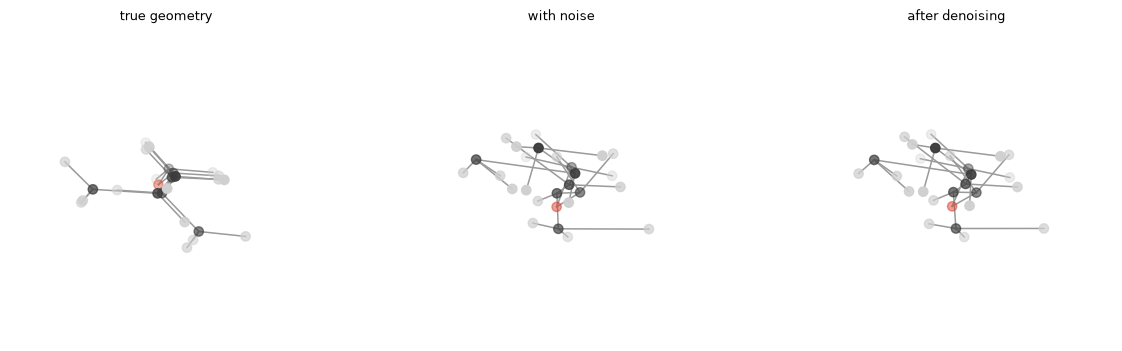

In [53]:
set_seed(1)
idx = QM9.te[:256]
z, pos, mask = QM9.Z[idx], QM9.pos[idx], QM9.mask[idx]
noisy = pos + (torch.rand_like(pos) * 2 - 1) * mask[..., None]
with torch.no_grad():
    fixed, _ = unimol_pre.denoise(z, noisy, mask)
    rmsd = lambda a, b: ((((a - b) * mask[..., None]) ** 2).sum((1, 2)) / (mask.sum(1) * 3)).sqrt()
    before, after = rmsd(noisy, pos).mean(), rmsd(fixed, pos).mean()
    Q, _ = torch.linalg.qr(torch.randn(3, 3, device=device))
    rot, _ = unimol_pre.denoise(z, noisy @ Q.T, mask)
    err = ((rot - fixed @ Q.T) * mask[..., None]).abs().max()
print(f'RMSD to the true geometry: {before:.4f} A before denoising, {after:.4f} A after '
      f'({(1 - after / before) * 100:.0f}% of the noise removed)')
print(f'equivariance of the coordinate head: |f(Qx) - Q f(x)| = {err:.2e}')

fig, axes = plt.subplots(1, 3, figsize=(12, 3.6), subplot_kw=dict(projection='3d'))
k = int(torch.argmax(mask.sum(1)))
n_at = int(mask[k].sum())
for ax, (p, title) in zip(axes, [(pos[k], 'true geometry'), (noisy[k], 'with noise'), (fixed[k], 'after denoising')]):
    p = p[:n_at].cpu().numpy()
    cols = ['#d0d0d0', '#3c3c3c', '#2a5fd6', '#d63a2a', '#1baf7a']
    ax.scatter(p[:, 0], p[:, 1], p[:, 2], c=[cols[int(QM9.Z[idx][k, a]) - 1] for a in range(n_at)], s=45)
    bond = QM9.bond[idx][k, :n_at, :n_at].cpu().numpy()
    for i in range(n_at):
        for j in range(i + 1, n_at):
            if bond[i, j]:
                ax.plot(*zip(p[i], p[j]), color='#9a9a9a', lw=1.1)
    ax.set_title(title, fontsize=9); ax.set_axis_off()
plt.tight_layout(); plt.show()

# 12. Summary

In [54]:
print('Part I -- recommendation (MovieLens)\n')
print(f"{'model':<26}{'recall@20':>11}{'ndcg@20':>10}{'params':>12}")
for name, r in RESULTS.items():
    print(f"{name:<26}{r['test']['recall@20']:>11.4f}{r['test']['ndcg@20']:>10.4f}{r.get('params', 0):>12,}")
print(f"\n{'ContextGNN (Gowalla)':<26}{'recall@20':>11}{'repeated':>10}{'new':>10}")
for name, r in CTX_RESULTS.items():
    print(f"{name:<26}{r['recall@20']:>11.4f}{r['repeat@20']:>10.4f}{r['new@20']:>10.4f}")

print('\n\nPart II -- molecules\n')
print(f"{'model':<26}{'Tox21 AUC':>11}{'ESOL RMSE':>11}{'params':>12}")
for name, r in MOL_RESULTS.items():
    print(f"{name:<26}{r['tox21']:>11.4f}{r['esol']:>11.4f}{r['params']:>12,}")
print(f"\n{'QM9, dipole moment':<26}{'MAE (D)':>11}{'params':>12}{'time':>8}")
for name, r in QM9_RESULTS.items():
    print(f"{name:<26}{r['test']:>11.4f}{r['params']:>12,}{r['time']:>7.0f}s")

Part I -- recommendation (MovieLens)

model                       recall@20   ndcg@20      params
Popularity                     0.0719    0.0616           0
MF (binary loss)               0.0762    0.0616     494,592
MF (BPR loss)                  0.0808    0.0689     494,592
NGCF (3 layers)                0.0813    0.0665     519,552
LightGCN (3 layers)            0.0955    0.0831     494,592
KGAT                           0.0815    0.0692     773,792

ContextGNN (Gowalla)        recall@20  repeated       new
Popularity (last 21 days)      0.0891    0.1382    0.0650
Go back where you went         0.2938    0.8550    0.0057
Two-tower                      0.0957    0.1393    0.0721
Pair-wise only                 0.2456    0.7195    0.0057
ContextGNN (fused)             0.2967    0.8118    0.0340


Part II -- molecules

model                       Tox21 AUC  ESOL RMSE      params
GCN                            0.7466     1.1041     107,276
GraphSAGE                      0.7371     1.353

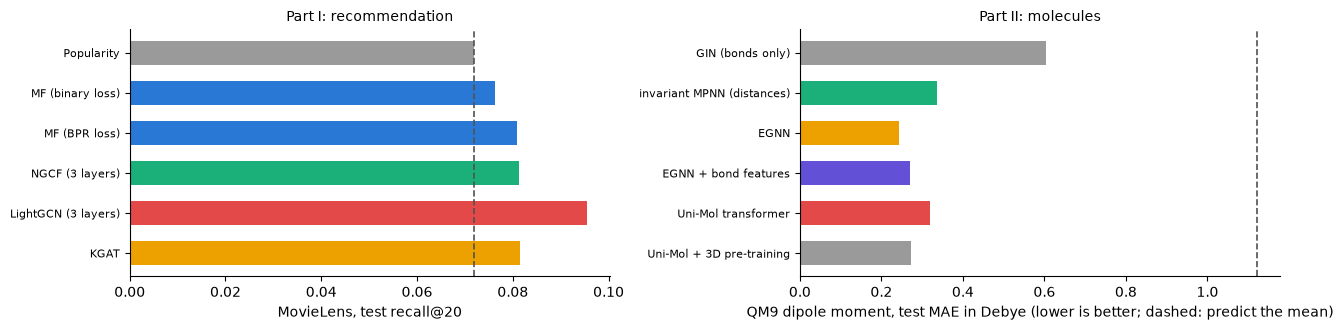

In [55]:
fig, axes = plt.subplots(1, 2, figsize=(13, 3.4))
names = list(RESULTS)
axes[0].barh(range(len(names)), [RESULTS[n]['test']['recall@20'] for n in names],
             color=[COLORS.get(RESULTS[n]['family'], '#9a9a9a') for n in names], height=0.6)
axes[0].axvline(RESULTS['Popularity']['test']['recall@20'], color='#52514e', ls='--', lw=1.2)
axes[0].set_yticks(range(len(names))); axes[0].set_yticklabels(names, fontsize=8); axes[0].invert_yaxis()
axes[0].set_xlabel('MovieLens, test recall@20'); axes[0].set_title('Part I: recommendation', fontsize=10)

names = list(QM9_RESULTS)
axes[1].barh(range(len(names)), [QM9_RESULTS[n]['test'] for n in names],
             color=['#9a9a9a', '#1baf7a', '#eda100', '#6250d6', '#e34948'][:len(names)], height=0.6)
axes[1].axvline((QM9.y[QM9.te] - QM9.mu).abs().mean().item(), color='#52514e', ls='--', lw=1.2)
axes[1].set_yticks(range(len(names))); axes[1].set_yticklabels(names, fontsize=8); axes[1].invert_yaxis()
axes[1].set_xlabel('QM9 dipole moment, test MAE in Debye (lower is better; dashed: predict the mean)')
axes[1].set_title('Part II: molecules', fontsize=10)
for ax in axes:
    ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout(); plt.show()